# RealSense D435i RGB global detection


In [1]:
"""Rule-based global RGB detection for mechanical parts on a white worktable.

Test image:
    realsense_color_20260605_181847.png

The detector intentionally uses only RGB data. It is organized so the masks and
geometry thresholds can later be reused in an RGB-D eye-in-hand workflow.
"""


'Rule-based global RGB detection for mechanical parts on a white worktable.\n\nTest image:\n    realsense_color_20260605_181847.png\n\nThe detector intentionally uses only RGB data. It is organized so the masks and\ngeometry thresholds can later be reused in an RGB-D eye-in-hand workflow.\n'

## Part 1: imports and parameters

In [2]:
from __future__ import annotations

import csv
import itertools
import json
import math
from pathlib import Path
from typing import Any

import cv2
import matplotlib.pyplot as plt
import numpy as np


def find_project_root() -> Path:
    """Find the project directory without relying on a machine-specific path."""
    current = Path.cwd().resolve()
    for candidate in (current, *current.parents):
        if (candidate / "global_rgb_part_detection.ipynb").is_file():
            return candidate
    return current


ROOT = find_project_root()
IMAGE_PATH = Path("realsense_pic") / "realsense_color_20260618_135941.png"
OUTPUT_DIR = ROOT / "output" / "global_detection"

# Manual mask is preferred for the current fixed global camera view.
USE_MANUAL_WORK_AREA = True
MANUAL_WORK_AREA_POLYGON = np.array(
    [
        [20, 0],
        [620, 0],
        [620, 480],
        [20, 480],
    ],
    dtype=np.int32,
)
WORK_MASK_ERODE_PX = 3

# Red segmentation: OpenCV hue range is [0, 179].
# Lower S/V thresholds make dark-red Gear_large teeth survive dim lighting.
RED_MIN_SATURATION = 50
RED_MIN_VALUE = 40
RED_MIN_CHANNEL_MARGIN = 8
RED_HSV_LOW_1 = (0, RED_MIN_SATURATION, RED_MIN_VALUE)
RED_HSV_HIGH_1 = (12, 255, 255)
RED_HSV_LOW_2 = (168, RED_MIN_SATURATION, RED_MIN_VALUE)
RED_HSV_HIGH_2 = (179, 255, 255)
USE_RED_MASK_DENOISE = True
RED_DENOISE_DIAMETER = 5
RED_DENOISE_SIGMA_COLOR = 35
RED_DENOISE_SIGMA_SPACE = 35
RED_OPEN_KERNEL_SIZE = 3
RED_CLOSE_KERNEL_SIZE = 7
RED_CLOSE_ITERATIONS = 2
RED_DILATE_KERNEL_SIZE = 3
RED_DILATE_ITERATIONS = 1
RED_MIN_AREA_PX = 180
RED_MAX_AREA_PX = 30000
# Gear contours are much larger than the screw. This rejects thin red base
# reflections/fragments without changing the three real gear thresholds.
RED_GEAR_MIN_AREA_PX = 2500
RED_SCREW_MAX_AREA_PX = 1500
RED_SCREW_MAX_DIM_PX = 65
RED_SCREW_MIN_AREA_PX = 260
RED_SCREW_MIN_CIRCULARITY = 0.42
RED_SCREW_MIN_EXTENT = 0.30
RED_SCREW_MIN_DISTANCE_FROM_SHAFT_PX = 24.0
RED_HOLE_MIN_AREA_PX = 90
RED_GEAR_SMALL_MAX_EQ_DIAMETER_PX = 125

# White shaft segmentation and filtering.
WHITE_SHAFT_MAX_SATURATION = 85
WHITE_SHAFT_MIN_VALUE = 118
WHITE_SHAFT_MIN_L = 118
WHITE_SHAFT_LAB_A_TOLERANCE = 28
WHITE_SHAFT_LAB_B_TOLERANCE = 35
# White shaft geometry is intentionally independent from black-object filters.
# The small shaft can be dim/partially segmented under fixed global RGB settings,
# so strict candidates are preferred but a relaxed fallback is allowed.
WHITE_SHAFT_STRICT_MIN_AREA_PX = 420
WHITE_SHAFT_RELAXED_MIN_AREA_PX = 180
WHITE_SHAFT_MAX_AREA_PX = 5000
WHITE_SHAFT_STRICT_MIN_RECTANGULARITY = 0.58
WHITE_SHAFT_RELAXED_MIN_RECTANGULARITY = 0.36
WHITE_SHAFT_STRICT_MIN_SHORT_SIDE_PX = 14
WHITE_SHAFT_RELAXED_MIN_SHORT_SIDE_PX = 8
WHITE_SHAFT_MAX_LONG_SIDE_PX = 120
WHITE_SHAFT_MAX_ASPECT_RATIO = 4.2
WHITE_SHAFT_MIN_SCORE = 2.55
WHITE_SHAFT_RELAXED_MIN_SCORE = 2.05

# Black object segmentation for insert-hole detection.
BLACK_MAX_VALUE = 82
BLACK_MIN_AREA_PX = 550
BLACK_MAX_AREA_PX = 4200
BLACK_MIN_RECTANGULARITY = 0.68
BLACK_MAX_LONG_SIDE_PX = 90
BLACK_MIN_SHORT_SIDE_PX = 18
BLACK_MAX_CIRCULARITY_FOR_ROUND_BLOB = 0.86
EXPECTED_SHAFT_COUNT = 2

# True black insert-hole filtering inside the detected base contour.
# This threshold is intentionally separate from BLACK_MAX_VALUE. Base holes can
# look brighter under the silver-base illumination, while shaft segmentation
# should remain strict.
BASE_INSERT_HOLE_MAX_VALUE = 100
BASE_INSERT_HOLE_OPEN_KERNEL = 3
BASE_INSERT_HOLE_CLOSE_KERNEL = 3
BASE_INSERT_HOLE_MIN_AREA = 220
BASE_INSERT_HOLE_MAX_AREA = 2000
BASE_INSERT_HOLE_MIN_RADIUS = 5.0
BASE_INSERT_HOLE_MAX_RADIUS = 30.0
BASE_INSERT_HOLE_MIN_CIRCULARITY = 0.74
BASE_INSERT_HOLE_MIN_ASPECT_RATIO = 0.55
BASE_INSERT_HOLE_MIN_ELLIPSE_ASPECT_RATIO = 0.62
BASE_INSERT_HOLE_MIN_ENCLOSING_FILL_RATIO = 0.50
BASE_INSERT_HOLE_MIN_RING_SCORE = 0.22
BASE_INSERT_HOLE_MIN_BOUNDARY_DISTANCE = 3.0
BASE_INSERT_HOLE_EXPECTED_COUNT = 3

# Perspective fallback used only when the strict contour rules find fewer
# than three holes. It accepts a moderately elongated dark core, then chooses
# the candidate farthest from already accepted holes.
BASE_INSERT_HOLE_RELAXED_MIN_AREA = 100
BASE_INSERT_HOLE_RELAXED_MIN_CIRCULARITY = 0.65
BASE_INSERT_HOLE_RELAXED_MIN_ASPECT_RATIO = 0.48
BASE_INSERT_HOLE_RELAXED_MIN_DISTANCE_PX = 35.0

# Silver base segmentation.
SILVER_MAX_SATURATION = 95
SILVER_MIN_VALUE = 85
SILVER_MAX_VALUE = 245
SILVER_MIN_L = 95
SILVER_MAX_L = 235
SILVER_LAB_A_TOLERANCE = 35
SILVER_LAB_B_TOLERANCE = 45
BASE_MIN_AREA_PX = 5000
BASE_MAX_AREA_PX = 60000
BASE_HOLE_MIN_RADIUS_PX = 12
BASE_HOLE_MAX_RADIUS_PX = 31
BASE_HOLE_HOUGH_PARAM2 = 18

# General filtering.
IMAGE_BORDER_MARGIN_PX = 5
MASK_EXCLUSION_DILATE_PX = 7
BASE_MIN_BORDER_VISIBLE_AREA_PX = 3200
BASE_MIN_BORDER_RECT_AREA_PX = 9000
BASE_BLACK_EXCLUSION_MAX_COMPONENT_AREA_PX = 2600

# Output files.
ANNOTATED_PATH = OUTPUT_DIR / "global_detection_result_black_holes.png"
DEBUG_PATH = OUTPUT_DIR / "global_detection_debug_black_holes.png"
CSV_PATH = OUTPUT_DIR / "global_detection_results.csv"
JSON_PATH = OUTPUT_DIR / "global_detection_results.json"


## Part 2: image loading and optional work-area mask

In [3]:
def load_image(path: str | Path) -> np.ndarray:
    """Load a BGR image from common project-relative locations."""
    requested = Path(path)
    candidates = [
        requested,
        ROOT / requested,
        ROOT / "realsense_pic" / requested.name,
        ROOT / "pic" / requested.name,
    ]
    for candidate in candidates:
        if not candidate.is_file():
            continue
        image = cv2.imread(str(candidate))
        if image is not None:
            print(f"Loaded image: {candidate}")
            return image
    raise FileNotFoundError(
        f"Cannot read {path}. Checked: " + ", ".join(str(p) for p in candidates)
    )


def _auto_detect_white_table(image: np.ndarray) -> np.ndarray:
    """Fallback work-area mask based on the largest bright, low-saturation area."""
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    white = cv2.inRange(hsv, (0, 0, 145), (179, 90, 255))
    close_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (31, 31))
    white = cv2.morphologyEx(white, cv2.MORPH_CLOSE, close_kernel, iterations=2)

    contours, _ = cv2.findContours(white, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    mask = np.zeros(image.shape[:2], dtype=np.uint8)
    if not contours:
        print("Warning: automatic table detection failed; using the full image.")
        mask[:] = 255
        return mask

    table_contour = max(contours, key=cv2.contourArea)
    hull = cv2.convexHull(table_contour)
    cv2.drawContours(mask, [hull], -1, 255, thickness=-1)
    return mask


def create_work_area_mask(image: np.ndarray) -> np.ndarray:
    """Create the preferred manual polygon mask or an automatic white-table mask."""
    height, width = image.shape[:2]
    mask = np.zeros((height, width), dtype=np.uint8)

    if USE_MANUAL_WORK_AREA and MANUAL_WORK_AREA_POLYGON is not None:
        polygon = MANUAL_WORK_AREA_POLYGON.copy()
        polygon[:, 0] = np.clip(polygon[:, 0], 0, width - 1)
        polygon[:, 1] = np.clip(polygon[:, 1], 0, height - 1)
        cv2.fillPoly(mask, [polygon], 255)
    else:
        mask = _auto_detect_white_table(image)

    if WORK_MASK_ERODE_PX > 0:
        size = 2 * WORK_MASK_ERODE_PX + 1
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (size, size))
        mask = cv2.erode(mask, kernel, iterations=1)
    return mask


## Part 3: color segmentation utilities

In [4]:
def _odd_kernel(size: int) -> np.ndarray:
    size = max(1, int(size))
    if size % 2 == 0:
        size += 1
    return cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (size, size))


def _remove_small_components(mask: np.ndarray, min_area: int) -> np.ndarray:
    count, labels, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    clean = np.zeros_like(mask)
    for label in range(1, count):
        if stats[label, cv2.CC_STAT_AREA] >= min_area:
            clean[labels == label] = 255
    return clean


def _keep_components_by_area(
    mask: np.ndarray,
    min_area: int = 1,
    max_area: int | None = None,
) -> np.ndarray:
    count, labels, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    clean = np.zeros_like(mask)
    for label in range(1, count):
        area = int(stats[label, cv2.CC_STAT_AREA])
        if area < min_area:
            continue
        if max_area is not None and area > max_area:
            continue
        clean[labels == label] = 255
    return clean


def _red_mask_debug_overlay(image: np.ndarray, red_mask: np.ndarray) -> np.ndarray:
    """Overlay the final red mask on the original image for live debugging."""
    red_layer = np.zeros_like(image)
    red_layer[:, :, 2] = 255
    blended = cv2.addWeighted(image, 0.65, red_layer, 0.35, 0.0)
    overlay = image.copy()
    overlay[red_mask > 0] = blended[red_mask > 0]
    return overlay


def segment_red_objects(
    image: np.ndarray,
    work_mask: np.ndarray,
    return_debug: bool = False,
) -> np.ndarray | tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Segment red objects using both ends of the HSV hue interval."""
    # Denoise only the segmentation input so annotated output stays unchanged.
    segmentation_image = (
        cv2.bilateralFilter(
            image,
            RED_DENOISE_DIAMETER,
            RED_DENOISE_SIGMA_COLOR,
            RED_DENOISE_SIGMA_SPACE,
        )
        if USE_RED_MASK_DENOISE else image
    )
    hsv = cv2.cvtColor(segmentation_image, cv2.COLOR_BGR2HSV)
    red_1 = cv2.inRange(hsv, RED_HSV_LOW_1, RED_HSV_HIGH_1)
    red_2 = cv2.inRange(hsv, RED_HSV_LOW_2, RED_HSV_HIGH_2)
    red_raw = cv2.bitwise_or(red_1, red_2)
    blue, green, red_channel = cv2.split(segmentation_image)
    red_dominant = (
        (red_channel.astype(np.int16) >= green.astype(np.int16) + RED_MIN_CHANNEL_MARGIN)
        & (red_channel.astype(np.int16) >= blue.astype(np.int16) + RED_MIN_CHANNEL_MARGIN)
    )
    red_raw[~red_dominant] = 0
    red_raw = cv2.bitwise_and(red_raw, work_mask)

    # Keep isolated background noise out, then bridge dark-red gear gaps.
    red = cv2.morphologyEx(
        red_raw, cv2.MORPH_OPEN, _odd_kernel(RED_OPEN_KERNEL_SIZE)
    )
    red = cv2.morphologyEx(
        red,
        cv2.MORPH_CLOSE,
        _odd_kernel(RED_CLOSE_KERNEL_SIZE),
        iterations=RED_CLOSE_ITERATIONS,
    )
    red = cv2.dilate(
        red,
        _odd_kernel(RED_DILATE_KERNEL_SIZE),
        iterations=RED_DILATE_ITERATIONS,
    )
    red = cv2.bitwise_and(red, work_mask)
    red = _remove_small_components(red, RED_MIN_AREA_PX)
    if return_debug:
        return red, red_raw, _red_mask_debug_overlay(image, red)
    return red


def segment_black_objects(image: np.ndarray, work_mask: np.ndarray) -> np.ndarray:
    """Segment dark objects; geometric filtering later rejects circular base holes."""
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    black = cv2.inRange(hsv, (0, 0, 0), (179, 255, BLACK_MAX_VALUE))
    black = cv2.bitwise_and(black, work_mask)
    black = cv2.morphologyEx(black, cv2.MORPH_OPEN, _odd_kernel(3))
    black = cv2.morphologyEx(black, cv2.MORPH_CLOSE, _odd_kernel(5))
    return _remove_small_components(black, 80)


def segment_white_shafts(image: np.ndarray, work_mask: np.ndarray) -> np.ndarray:
    """Segment the two white shaft parts on the black background."""
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)
    _, saturation, value = cv2.split(hsv)
    lightness, a_channel, b_channel = cv2.split(lab)
    neutral = (
        (np.abs(a_channel.astype(np.int16) - 128) <= WHITE_SHAFT_LAB_A_TOLERANCE)
        & (np.abs(b_channel.astype(np.int16) - 128) <= WHITE_SHAFT_LAB_B_TOLERANCE)
    )
    white = (
        neutral
        & (saturation <= WHITE_SHAFT_MAX_SATURATION)
        & (value >= WHITE_SHAFT_MIN_VALUE)
        & (lightness >= WHITE_SHAFT_MIN_L)
    )
    mask = cv2.bitwise_and(np.uint8(white) * 255, work_mask)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, _odd_kernel(3))
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, _odd_kernel(5))
    return _remove_small_components(mask, 80)


def segment_silver_base(
    image: np.ndarray,
    work_mask: np.ndarray,
    red_mask: np.ndarray,
    black_mask: np.ndarray,
) -> np.ndarray:
    """Segment neutral gray/silver pixels while avoiding full-background black cuts."""
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)

    _, saturation, value = cv2.split(hsv)
    lab_l, lab_a, lab_b = cv2.split(lab)
    neutral_lab = (
        (np.abs(lab_a.astype(np.int16) - 128) <= SILVER_LAB_A_TOLERANCE)
        & (np.abs(lab_b.astype(np.int16) - 128) <= SILVER_LAB_B_TOLERANCE)
    )
    gray_hsv = (
        (saturation <= SILVER_MAX_SATURATION)
        & (value >= SILVER_MIN_VALUE)
        & (value <= SILVER_MAX_VALUE)
        & (lab_l >= SILVER_MIN_L)
        & (lab_l <= SILVER_MAX_L)
    )
    silver = np.uint8(neutral_lab & gray_hsv) * 255
    silver = cv2.bitwise_and(silver, work_mask)

    local_black_holes = _keep_components_by_area(
        black_mask,
        min_area=BASE_INSERT_HOLE_RELAXED_MIN_AREA,
        max_area=BASE_BLACK_EXCLUSION_MAX_COMPONENT_AREA_PX,
    )
    exclusion = cv2.bitwise_or(red_mask, local_black_holes)
    exclusion = cv2.dilate(exclusion, _odd_kernel(MASK_EXCLUSION_DILATE_PX))
    silver[exclusion > 0] = 0

    silver = cv2.morphologyEx(silver, cv2.MORPH_OPEN, _odd_kernel(3))
    silver = cv2.morphologyEx(
        silver, cv2.MORPH_CLOSE, _odd_kernel(11), iterations=1
    )
    return _remove_small_components(silver, 250)


def _contour_touches_image_border(
    contour: np.ndarray, image_shape: tuple[int, ...]
) -> bool:
    x, y, width, height = cv2.boundingRect(contour)
    image_height, image_width = image_shape[:2]
    return (
        x <= IMAGE_BORDER_MARGIN_PX
        or y <= IMAGE_BORDER_MARGIN_PX
        or x + width >= image_width - IMAGE_BORDER_MARGIN_PX
        or y + height >= image_height - IMAGE_BORDER_MARGIN_PX
    )


def _contour_center(contour: np.ndarray) -> tuple[float, float]:
    moments = cv2.moments(contour)
    if abs(moments["m00"]) > 1e-8:
        return (
            float(moments["m10"] / moments["m00"]),
            float(moments["m01"] / moments["m00"]),
        )
    x, y, width, height = cv2.boundingRect(contour)
    return x + width / 2.0, y + height / 2.0


def _estimate_hole_center(contour: np.ndarray) -> tuple[float, float]:
    """Estimate a hole center from its fitted ellipse or enclosing circle."""
    if len(contour) >= 5:
        try:
            (center_u, center_v), _, _ = cv2.fitEllipse(contour)
            if math.isfinite(center_u) and math.isfinite(center_v):
                return float(center_u), float(center_v)
        except cv2.error:
            pass
    try:
        (center_u, center_v), _ = cv2.minEnclosingCircle(contour)
        if math.isfinite(center_u) and math.isfinite(center_v):
            return float(center_u), float(center_v)
    except cv2.error:
        pass
    return _contour_center(contour)


def compute_rotated_rect_features(contour: np.ndarray) -> dict[str, Any]:
    """Return minAreaRect geometry with long-side yaw normalized to [-90, 90)."""
    rect = cv2.minAreaRect(contour)
    (center_u, center_v), (raw_width, raw_height), raw_angle = rect
    box = cv2.boxPoints(rect).astype(np.float32)

    if raw_width >= raw_height:
        long_side = float(raw_width)
        short_side = float(raw_height)
        yaw_deg = float(raw_angle)
    else:
        long_side = float(raw_height)
        short_side = float(raw_width)
        yaw_deg = float(raw_angle + 90.0)
    yaw_deg = ((yaw_deg + 90.0) % 180.0) - 90.0

    edge_midpoints = []
    edge_lengths = []
    for index in range(4):
        point_a = box[index]
        point_b = box[(index + 1) % 4]
        edge_midpoints.append(((point_a + point_b) / 2.0).tolist())
        edge_lengths.append(float(np.linalg.norm(point_b - point_a)))

    angle_rad = math.radians(yaw_deg)
    direction = np.array([math.cos(angle_rad), math.sin(angle_rad)])
    center = np.array([center_u, center_v], dtype=np.float64)
    grasp_offset = 0.22 * long_side
    grasp_candidates = [
        center.tolist(),
        (center + grasp_offset * direction).tolist(),
        (center - grasp_offset * direction).tolist(),
    ]

    return {
        "center": [float(center_u), float(center_v)],
        "raw_size": [float(raw_width), float(raw_height)],
        "long_side_px": long_side,
        "short_side_px": short_side,
        "yaw_deg": yaw_deg,
        "box_points": box.tolist(),
        "edge_midpoints_2d": edge_midpoints,
        "edge_lengths_px": edge_lengths,
        "grasp_candidates_2d": grasp_candidates,
    }


def _basic_contour_features(contour: np.ndarray) -> dict[str, float | int]:
    area = float(cv2.contourArea(contour))
    perimeter = float(cv2.arcLength(contour, True))
    x, y, width, height = cv2.boundingRect(contour)
    hull_area = float(cv2.contourArea(cv2.convexHull(contour)))
    circularity = 4.0 * math.pi * area / (perimeter * perimeter) if perimeter else 0.0
    extent = area / float(width * height) if width and height else 0.0
    solidity = area / hull_area if hull_area else 0.0
    equivalent_diameter = math.sqrt(4.0 * area / math.pi) if area else 0.0
    approx = cv2.approxPolyDP(contour, 0.01 * perimeter, True)
    return {
        "area": area,
        "perimeter": perimeter,
        "bbox_x": int(x),
        "bbox_y": int(y),
        "bbox_w": int(width),
        "bbox_h": int(height),
        "circularity": float(circularity),
        "extent": float(extent),
        "solidity": float(solidity),
        "equivalent_diameter": float(equivalent_diameter),
        "contour_complexity": int(len(approx)),
    }


def _find_holes_inside_contour(
    contour: np.ndarray, object_mask: np.ndarray
) -> list[np.ndarray]:
    filled = np.zeros_like(object_mask)
    cv2.drawContours(filled, [contour], -1, 255, thickness=-1)
    holes = cv2.bitwise_and(filled, cv2.bitwise_not(object_mask))
    hole_contours, _ = cv2.findContours(
        holes, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    return [
        hole
        for hole in hole_contours
        if cv2.contourArea(hole) >= RED_HOLE_MIN_AREA_PX
    ]


def _find_inner_square_center(
    contour: np.ndarray, red_mask: np.ndarray
) -> list[float] | None:
    object_center = np.array(_contour_center(contour))
    candidates = []
    for hole in _find_holes_inside_contour(contour, red_mask):
        perimeter = cv2.arcLength(hole, True)
        approx = cv2.approxPolyDP(hole, 0.04 * perimeter, True)
        area = cv2.contourArea(hole)
        if 4 <= len(approx) <= 6 and 100 <= area <= 3500:
            center = np.array(_contour_center(hole))
            candidates.append((float(np.linalg.norm(center - object_center)), center))
    if not candidates:
        return None
    _, center = min(candidates, key=lambda item: item[0])
    return [float(center[0]), float(center[1])]


def _new_result(
    class_name: str,
    contour: np.ndarray,
    confidence: str,
    rule_note: str,
) -> dict[str, Any]:
    features = _basic_contour_features(contour)
    rotated = compute_rotated_rect_features(contour)
    center_u, center_v = _contour_center(contour)
    return {
        "class_name": class_name,
        "center_u": round(center_u, 2),
        "center_v": round(center_v, 2),
        "bbox_x": features["bbox_x"],
        "bbox_y": features["bbox_y"],
        "bbox_w": features["bbox_w"],
        "bbox_h": features["bbox_h"],
        "area_px": round(float(features["area"]), 1),
        "yaw_deg": round(float(rotated["yaw_deg"]), 2),
        "confidence": confidence,
        "rule_note": rule_note,
        "type_certain": bool(confidence == "high"),
        "classification_status": ("certain" if confidence == "high" else "uncertain"),
        "classification_reason": rule_note,
        "classification_set_complete": None,
        "gear_outer_radius_px": None,
        "gear_inner_square_center": None,
        "grasp_hint_2d": None,
        "rect_width_px": None,
        "rect_height_px": None,
        "long_side_px": None,
        "short_side_px": None,
        "edge_midpoints_2d": None,
        "grasp_candidates_2d": None,
        "base_contour_area": None,
        "base_rotated_rect": None,
        "base_hole_candidates_2d": None,
        "_contour": contour,
        "_rotated_rect": rotated,
        "_features": features,
    }


## Part 4: red object detection and classification

In [5]:
def classify_red_part(
    contour: np.ndarray, image: np.ndarray, red_mask: np.ndarray | None = None
) -> tuple[str, str, str]:
    """Classify one red contour using size, holes, and gear-like complexity."""
    del image  # Reserved for future texture-based rules.
    features = _basic_contour_features(contour)
    max_dim = max(features["bbox_w"], features["bbox_h"])
    holes = _find_holes_inside_contour(contour, red_mask) if red_mask is not None else []
    hole_count = len(holes)

    if (
        RED_SCREW_MIN_AREA_PX <= features["area"] <= RED_SCREW_MAX_AREA_PX
        and max_dim <= RED_SCREW_MAX_DIM_PX
        and features["circularity"] >= RED_SCREW_MIN_CIRCULARITY
        and features["extent"] >= RED_SCREW_MIN_EXTENT
    ):
        return "Screw", "high", "small red component; compact non-gear geometry"

    if hole_count >= 3:
        return (
            "Gear_large",
            "high",
            f"large gear-like contour with {hole_count} significant internal holes",
        )

    if (
        features["equivalent_diameter"] <= RED_GEAR_SMALL_MAX_EQ_DIAMETER_PX
        and hole_count >= 1
    ):
        return (
            "Gear_small",
            "high",
            "medium red gear-like contour with a central hole",
        )

    if features["area"] > 6000 and hole_count <= 2:
        return (
            "Gear_compound",
            "medium",
            "large gear-like contour; compound structure inferred by size and few through-holes",
        )

    return "Gear_small", "medium", "red gear candidate classified mainly by size"


def _mask_distance_at_point(mask: np.ndarray, point: tuple[float, float]) -> float:
    x = int(round(point[0]))
    y = int(round(point[1]))
    if x < 0 or y < 0 or y >= mask.shape[0] or x >= mask.shape[1]:
        return 0.0
    if mask[y, x] > 0:
        return 0.0
    outside = np.uint8(mask == 0) * 255
    distance = cv2.distanceTransform(outside, cv2.DIST_L2, 3)
    return float(distance[y, x])


def detect_red_parts(
    image: np.ndarray,
    red_mask: np.ndarray,
    screw_reject_mask: np.ndarray | None = None,
) -> list[dict[str, Any]]:
    """Detect red components, then refine the three gear labels jointly."""
    contours, _ = cv2.findContours(red_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    candidates = []
    for contour in contours:
        area = cv2.contourArea(contour)
        if not RED_MIN_AREA_PX <= area <= RED_MAX_AREA_PX:
            continue
        class_name, confidence, note = classify_red_part(contour, image, red_mask)
        if class_name != "Screw" and area < RED_GEAR_MIN_AREA_PX:
            continue
        if class_name == "Screw" and screw_reject_mask is not None:
            screw_center = cv2.minAreaRect(contour)[0]
            shaft_distance = _mask_distance_at_point(screw_reject_mask, screw_center)
            if shaft_distance < RED_SCREW_MIN_DISTANCE_FROM_SHAFT_PX:
                continue
        result = _new_result(class_name, contour, confidence, note)
        if class_name == "Screw":
            # A painted black top removes red pixels asymmetrically. The
            # minAreaRect center follows the outer screw silhouette better
            # than the red-area centroid.
            screw_center = cv2.minAreaRect(contour)[0]
            result["center_u"] = round(float(screw_center[0]), 2)
            result["center_v"] = round(float(screw_center[1]), 2)
            result["rule_note"] += "; center from red outer-shape minAreaRect"
        holes = _find_holes_inside_contour(contour, red_mask)
        result["_hole_count"] = len(holes)
        result["_hole_areas"] = [float(cv2.contourArea(hole)) for hole in holes]
        candidates.append(result)

    # Refine labels using relative geometry when exactly three gear candidates exist.
    gear_candidates = [item for item in candidates if item["class_name"] != "Screw"]
    if len(gear_candidates) == 3:
        large = max(gear_candidates, key=lambda item: (item["_hole_count"], item["area_px"]))
        remaining = [item for item in gear_candidates if item is not large]
        compound = max(remaining, key=lambda item: item["area_px"])
        small = min(remaining, key=lambda item: item["area_px"])

        large["class_name"] = "Gear_large"
        large["confidence"] = "high" if large["_hole_count"] >= 3 else "medium"
        large["rule_note"] = (
            f"largest multi-hole gear; {large['_hole_count']} significant holes"
        )
        small["class_name"] = "Gear_small"
        small["confidence"] = "high" if small["_hole_count"] >= 1 else "medium"
        small["rule_note"] = "smallest gear candidate; central-hole evidence included"
        compound["class_name"] = "Gear_compound"
        compound["confidence"] = "medium"
        compound["rule_note"] = (
            "large remaining gear with few through-holes; size/structure fallback, "
            "not y-position only"
        )
        for gear in gear_candidates:
            gear["type_certain"] = True
            gear["classification_status"] = "certain"
            gear["classification_set_complete"] = True
            gear["classification_reason"] = (
                "all three gear candidates detected; label refined jointly by "
                "hole structure and relative size"
            )
    else:
        for gear in gear_candidates:
            gear["type_certain"] = False
            gear["classification_status"] = "uncertain"
            gear["classification_set_complete"] = False
            gear["classification_reason"] = (
                f"only {len(gear_candidates)} of 3 expected gear candidates detected; "
                "class_name is an absolute-geometry best guess"
            )
            if gear["confidence"] == "high":
                gear["confidence"] = "medium"

    for result in candidates:
        if result["class_name"].startswith("Gear"):
            contour = result["_contour"]
            (_, _), radius = cv2.minEnclosingCircle(contour)
            square_center = _find_inner_square_center(contour, red_mask)
            result["gear_outer_radius_px"] = round(float(radius), 2)
            result["gear_inner_square_center"] = square_center
            if square_center is not None:
                result["center_u"] = round(float(square_center[0]), 2)
                result["center_v"] = round(float(square_center[1]), 2)
                result["rule_note"] += "; center from inner square"
            result["grasp_hint_2d"] = [
                round(float(result["center_u"]), 2),
                round(float(result["center_v"]), 2),
            ]

    return candidates


## Part 5: black shaft detection and classification

In [6]:
def classify_shaft(contour: np.ndarray) -> tuple[str, str, str]:
    """Provide a provisional shaft label; relative size is refined jointly."""
    rotated = compute_rotated_rect_features(contour)
    rect_area = rotated["long_side_px"] * rotated["short_side_px"]
    if rect_area >= 1450:
        return "Shaft_large", "high", "white rectangular component with larger rotated area"
    return "Shaft_small", "medium", "white rectangular component with smaller rotated area"


def _score_white_shaft_candidate(
    contour: np.ndarray,
    image_shape: tuple[int, ...],
    relaxed: bool = False,
) -> dict[str, Any] | None:
    """Score a white/gray rectangular candidate without using position priors."""
    features = _basic_contour_features(contour)
    min_area = (
        WHITE_SHAFT_RELAXED_MIN_AREA_PX
        if relaxed else WHITE_SHAFT_STRICT_MIN_AREA_PX
    )
    min_rectangularity = (
        WHITE_SHAFT_RELAXED_MIN_RECTANGULARITY
        if relaxed else WHITE_SHAFT_STRICT_MIN_RECTANGULARITY
    )
    min_short_side = (
        WHITE_SHAFT_RELAXED_MIN_SHORT_SIDE_PX
        if relaxed else WHITE_SHAFT_STRICT_MIN_SHORT_SIDE_PX
    )
    min_score = (
        WHITE_SHAFT_RELAXED_MIN_SCORE
        if relaxed else WHITE_SHAFT_MIN_SCORE
    )

    if not min_area <= features["area"] <= WHITE_SHAFT_MAX_AREA_PX:
        return None
    if _contour_touches_image_border(contour, image_shape):
        return None

    rotated = compute_rotated_rect_features(contour)
    rect_area = rotated["long_side_px"] * rotated["short_side_px"]
    if rect_area <= 0.0:
        return None
    rectangularity = features["area"] / rect_area
    long_side = float(rotated["long_side_px"])
    short_side = float(rotated["short_side_px"])
    aspect_ratio = long_side / max(short_side, 1e-6)

    # Reject circular highlights/holes and long slivers, but keep dim small shafts.
    looks_round = (
        features["circularity"] >= BLACK_MAX_CIRCULARITY_FOR_ROUND_BLOB
        and features["contour_complexity"] > 6
    )
    if looks_round:
        return None
    if rectangularity < min_rectangularity:
        return None
    if long_side > WHITE_SHAFT_MAX_LONG_SIDE_PX:
        return None
    if short_side < min_short_side:
        return None
    if aspect_ratio > WHITE_SHAFT_MAX_ASPECT_RATIO:
        return None

    area_score = min(float(features["area"]) / 900.0, 1.5)
    rect_score = min(rectangularity / max(min_rectangularity, 1e-6), 1.6)
    side_score = min(short_side / max(min_short_side, 1e-6), 1.4)
    aspect_score = max(0.0, 1.0 - max(aspect_ratio - 2.2, 0.0) / 2.0)
    score = area_score + rect_score + side_score + aspect_score
    if relaxed:
        score -= 0.25
    if score < min_score:
        return None

    class_name, confidence, note = classify_shaft(contour)
    if relaxed:
        confidence = "medium"
        note += "; relaxed white-shaft fallback candidate"
    result = _new_result(class_name, contour, confidence, note)
    result["_rect_area"] = rect_area
    result["_rectangularity"] = rectangularity
    result["_shaft_score"] = score
    result["_shaft_relaxed"] = relaxed
    result["rect_width_px"] = round(float(rotated["raw_size"][0]), 2)
    result["rect_height_px"] = round(float(rotated["raw_size"][1]), 2)
    result["long_side_px"] = round(long_side, 2)
    result["short_side_px"] = round(short_side, 2)
    result["edge_midpoints_2d"] = rotated["edge_midpoints_2d"]
    result["grasp_candidates_2d"] = rotated["grasp_candidates_2d"]
    result["rule_note"] += (
        f"; shaft_score={score:.2f}, rectangularity={rectangularity:.2f}, "
        f"aspect={aspect_ratio:.2f}"
    )
    return result


def _deduplicate_shaft_candidates(
    candidates: list[dict[str, Any]],
) -> list[dict[str, Any]]:
    """Keep the strongest candidates when strict and relaxed masks overlap."""
    sorted_candidates = sorted(
        candidates,
        key=lambda item: (item.get("_shaft_score", 0.0), item.get("_rect_area", 0.0)),
        reverse=True,
    )
    kept = []
    for candidate in sorted_candidates:
        center = np.array([candidate["center_u"], candidate["center_v"]], dtype=float)
        duplicate = False
        for existing in kept:
            other = np.array([existing["center_u"], existing["center_v"]], dtype=float)
            if float(np.linalg.norm(center - other)) < 12.0:
                duplicate = True
                break
        if not duplicate:
            kept.append(candidate)
    return kept


def detect_white_shafts(
    image: np.ndarray, white_shaft_mask: np.ndarray
) -> list[dict[str, Any]]:
    """Detect rectangular white shafts using appearance and geometry only."""
    strict_mask = cv2.morphologyEx(
        white_shaft_mask, cv2.MORPH_CLOSE, _odd_kernel(5), iterations=1
    )
    contours, _ = cv2.findContours(
        strict_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    shaft_candidates = []
    for contour in contours:
        candidate = _score_white_shaft_candidate(contour, image.shape, relaxed=False)
        if candidate is not None:
            shaft_candidates.append(candidate)

    if len(shaft_candidates) < EXPECTED_SHAFT_COUNT:
        relaxed_mask = cv2.morphologyEx(
            white_shaft_mask, cv2.MORPH_CLOSE, _odd_kernel(7), iterations=1
        )
        relaxed_mask = cv2.dilate(relaxed_mask, _odd_kernel(3), iterations=1)
        relaxed_contours, _ = cv2.findContours(
            relaxed_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
        )
        for contour in relaxed_contours:
            candidate = _score_white_shaft_candidate(
                contour, image.shape, relaxed=True
            )
            if candidate is not None:
                shaft_candidates.append(candidate)

    shaft_candidates = _deduplicate_shaft_candidates(shaft_candidates)
    shaft_candidates.sort(
        key=lambda item: (item["_shaft_score"], item["_rect_area"]), reverse=True
    )
    if len(shaft_candidates) > EXPECTED_SHAFT_COUNT:
        shaft_candidates = shaft_candidates[:EXPECTED_SHAFT_COUNT]

    shaft_candidates.sort(key=lambda item: item["_rect_area"], reverse=True)
    shaft_size_margin_ratio = None
    shaft_set_complete = len(shaft_candidates) == EXPECTED_SHAFT_COUNT
    if shaft_set_complete:
        shaft_size_margin_ratio = float(
            (shaft_candidates[0]["_rect_area"] - shaft_candidates[1]["_rect_area"])
            / max(shaft_candidates[0]["_rect_area"], 1e-6)
        )

    if len(shaft_candidates) >= 1:
        shaft_candidates[0]["class_name"] = "Shaft_large"
        shaft_candidates[0]["rule_note"] = (
            "largest of two valid white rectangular components"
            if shaft_set_complete else
            "only one shaft candidate detected; large label is provisional"
        ) + "; " + shaft_candidates[0]["rule_note"]
    if len(shaft_candidates) >= 2:
        shaft_candidates[1]["class_name"] = "Shaft_small"
        shaft_candidates[1]["rule_note"] = (
            "smaller of two valid white rectangular components; "
            + shaft_candidates[1]["rule_note"]
        )

    shaft_types_separated = bool(
        shaft_set_complete and shaft_size_margin_ratio is not None
        and shaft_size_margin_ratio >= 0.08
    )
    for shaft in shaft_candidates:
        shaft["shaft_size_margin_ratio"] = (
            round(shaft_size_margin_ratio, 4)
            if shaft_size_margin_ratio is not None else None
        )
        shaft["classification_set_complete"] = shaft_set_complete
        shaft["type_certain"] = shaft_types_separated
        shaft["classification_status"] = (
            "certain" if shaft_types_separated else "uncertain"
        )
        shaft["classification_reason"] = (
            "two shaft candidates detected with sufficient rotated-area separation"
            if shaft_types_separated else
            "shaft set incomplete or large/small rotated-area separation below 8%"
        )
        shaft["confidence"] = "high" if shaft_types_separated else shaft["confidence"]
    return shaft_candidates


## Part 6: silver base and black insert-hole detection

Base 外轮廓继续使用银色 mask；三个插孔严格从 `black_mask AND filled(base_contour)` 中检测。

In [7]:
def detect_base_insert_holes_from_black_mask(
    image: np.ndarray,
    base_contour: np.ndarray,
    black_mask: np.ndarray,
) -> tuple[list[dict[str, Any]], np.ndarray, np.ndarray, np.ndarray]:
    """Detect three insert holes using cleaned masks and robust ellipse centers."""
    base_roi_mask = np.zeros(image.shape[:2], dtype=np.uint8)
    cv2.drawContours(base_roi_mask, [base_contour], -1, 255, thickness=-1)

    # Keep the hole threshold local to the base so shaft segmentation is unchanged.
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)
    base_dark_mask = cv2.inRange(
        hsv, (0, 0, 0), (179, 255, BASE_INSERT_HOLE_MAX_VALUE)
    )
    hole_search_mask = cv2.bitwise_and(base_dark_mask, base_roi_mask)
    hole_search_mask = cv2.bitwise_or(
        hole_search_mask, cv2.bitwise_and(black_mask, base_roi_mask)
    )
    hole_search_mask = cv2.morphologyEx(
        hole_search_mask,
        cv2.MORPH_OPEN,
        _odd_kernel(BASE_INSERT_HOLE_OPEN_KERNEL),
    )
    hole_search_mask = cv2.morphologyEx(
        hole_search_mask,
        cv2.MORPH_CLOSE,
        _odd_kernel(BASE_INSERT_HOLE_CLOSE_KERNEL),
    )

    contours, _ = cv2.findContours(
        hole_search_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    base_rotated = compute_rotated_rect_features(base_contour)
    base_center = np.array(base_rotated["center"], dtype=np.float64)
    base_axis_rad = math.radians(float(base_rotated["yaw_deg"]))
    base_long_axis = np.array([math.cos(base_axis_rad), math.sin(base_axis_rad)])
    base_short_axis = np.array([-math.sin(base_axis_rad), math.cos(base_axis_rad)])
    base_long_half = max(float(base_rotated["long_side_px"]) * 0.5, 1.0)
    base_short_half = max(float(base_rotated["short_side_px"]) * 0.5, 1.0)

    def _local_base_coordinates(center_u: float, center_v: float) -> tuple[float, float, float]:
        center = np.array([center_u, center_v], dtype=np.float64)
        offset = center - base_center
        local_u = float(np.dot(offset, base_long_axis))
        local_v = float(np.dot(offset, base_short_axis))
        normalized_distance = math.hypot(local_u / base_long_half, local_v / base_short_half)
        return local_u, local_v, normalized_distance

    def _silver_ring_score(center_u: float, center_v: float, radius: float) -> float:
        outer_radius = int(round(max(radius + 9.0, radius * 1.55)))
        inner_radius = int(round(max(radius + 2.0, radius * 1.12)))
        if outer_radius <= inner_radius:
            return 0.0
        ring_mask = np.zeros(image.shape[:2], dtype=np.uint8)
        center = (int(round(center_u)), int(round(center_v)))
        cv2.circle(ring_mask, center, outer_radius, 255, thickness=-1)
        cv2.circle(ring_mask, center, inner_radius, 0, thickness=-1)
        ring_mask = cv2.bitwise_and(ring_mask, base_roi_mask)
        if cv2.countNonZero(ring_mask) < 20:
            return 0.0
        _, saturation, value = cv2.split(hsv)
        lab_l, lab_a, lab_b = cv2.split(lab)
        neutral_silver = (
            (ring_mask > 0)
            & (saturation <= SILVER_MAX_SATURATION + 25)
            & (value >= SILVER_MIN_VALUE)
            & (lab_l >= SILVER_MIN_L)
            & (np.abs(lab_a.astype(np.int16) - 128) <= SILVER_LAB_A_TOLERANCE + 10)
            & (np.abs(lab_b.astype(np.int16) - 128) <= SILVER_LAB_B_TOLERANCE + 10)
        )
        return float(np.count_nonzero(neutral_silver) / cv2.countNonZero(ring_mask))

    def _round_hole_candidate_count(test_contours):
        count = 0
        for test_contour in test_contours:
            area = float(cv2.contourArea(test_contour))
            perimeter = float(cv2.arcLength(test_contour, True))
            if perimeter <= 0.0:
                continue
            circularity = 4.0 * math.pi * area / (perimeter * perimeter)
            x, y, width, height = cv2.boundingRect(test_contour)
            aspect_ratio = min(width, height) / max(width, height) if max(width, height) else 0.0
            (_, _), radius = cv2.minEnclosingCircle(test_contour)
            fill_ratio = area / (math.pi * radius * radius) if radius > 1e-6 else 0.0
            center_u, center_v = _estimate_hole_center(test_contour)
            boundary_distance = cv2.pointPolygonTest(
                base_contour, (float(center_u), float(center_v)), True
            )
            if (
                BASE_INSERT_HOLE_MIN_AREA <= area <= BASE_INSERT_HOLE_MAX_AREA
                and BASE_INSERT_HOLE_MIN_RADIUS <= radius <= BASE_INSERT_HOLE_MAX_RADIUS
                and boundary_distance >= BASE_INSERT_HOLE_MIN_BOUNDARY_DISTANCE
                and circularity >= BASE_INSERT_HOLE_MIN_CIRCULARITY
                and aspect_ratio >= BASE_INSERT_HOLE_MIN_ASPECT_RATIO
                and fill_ratio >= BASE_INSERT_HOLE_MIN_ENCLOSING_FILL_RATIO
            ):
                count += 1
        return count

    strict_candidates = []
    relaxed_candidates = []
    for contour in contours:
        area = float(cv2.contourArea(contour))
        perimeter = float(cv2.arcLength(contour, True))
        circularity = (
            4.0 * math.pi * area / (perimeter * perimeter)
            if perimeter else 0.0
        )
        x, y, width, height = cv2.boundingRect(contour)
        aspect_ratio = (
            min(width, height) / max(width, height)
            if max(width, height) else 0.0
        )
        (_, _), radius = cv2.minEnclosingCircle(contour)
        fill_ratio = area / (math.pi * radius * radius) if radius > 1e-6 else 0.0
        center_u, center_v = _estimate_hole_center(contour)

        ellipse_major = 2.0 * float(radius)
        ellipse_minor = 2.0 * float(radius)
        if len(contour) >= 5:
            try:
                _, (ellipse_width, ellipse_height), _ = cv2.fitEllipse(contour)
                ellipse_major = max(float(ellipse_width), float(ellipse_height))
                ellipse_minor = min(float(ellipse_width), float(ellipse_height))
            except cv2.error:
                pass
        ellipse_aspect_ratio = (
            ellipse_minor / ellipse_major if ellipse_major > 1e-6 else 0.0
        )
        boundary_distance = cv2.pointPolygonTest(
            base_contour, (float(center_u), float(center_v)), True
        )
        local_u, local_v, base_center_distance = _local_base_coordinates(
            float(center_u), float(center_v)
        )
        ring_score = _silver_ring_score(float(center_u), float(center_v), float(radius))
        slot_like = bool(
            ellipse_aspect_ratio < BASE_INSERT_HOLE_MIN_ELLIPSE_ASPECT_RATIO
            or aspect_ratio < BASE_INSERT_HOLE_MIN_ASPECT_RATIO
            or fill_ratio < BASE_INSERT_HOLE_MIN_ENCLOSING_FILL_RATIO
        )

        if not (
            BASE_INSERT_HOLE_RELAXED_MIN_AREA
            <= area
            <= BASE_INSERT_HOLE_MAX_AREA
            and BASE_INSERT_HOLE_MIN_RADIUS
            <= radius
            <= BASE_INSERT_HOLE_MAX_RADIUS
            and boundary_distance >= BASE_INSERT_HOLE_MIN_BOUNDARY_DISTANCE
        ):
            continue
        if slot_like:
            continue

        circularity_score = min(
            max(
                (circularity - BASE_INSERT_HOLE_MIN_CIRCULARITY)
                / max(1.0 - BASE_INSERT_HOLE_MIN_CIRCULARITY, 1e-6),
                0.0,
            ),
            1.0,
        )
        ellipse_score = min(
            max(
                (ellipse_aspect_ratio - BASE_INSERT_HOLE_MIN_ELLIPSE_ASPECT_RATIO)
                / max(1.0 - BASE_INSERT_HOLE_MIN_ELLIPSE_ASPECT_RATIO, 1e-6),
                0.0,
            ),
            1.0,
        )
        radius_midpoint = 0.5 * (
            BASE_INSERT_HOLE_MIN_RADIUS + BASE_INSERT_HOLE_MAX_RADIUS
        )
        radius_half_range = 0.5 * (
            BASE_INSERT_HOLE_MAX_RADIUS - BASE_INSERT_HOLE_MIN_RADIUS
        )
        radius_score = max(
            0.0, 1.0 - abs(radius - radius_midpoint) / radius_half_range
        )
        boundary_score = min(max(boundary_distance / 25.0, 0.0), 1.0)
        area_score = min(area / BASE_INSERT_HOLE_MAX_AREA, 1.0)
        ring_score_clamped = min(max(ring_score, 0.0), 1.0)
        center_score = max(0.0, 1.0 - base_center_distance)
        score = (
            0.30 * ring_score_clamped
            + 0.25 * circularity_score
            + 0.20 * ellipse_score
            + 0.10 * boundary_score
            + 0.10 * radius_score
            + 0.05 * area_score
        )
        candidate = {
            "contour": contour,
            "center_u": float(center_u),
            "center_v": float(center_v),
            "radius_px": float(radius),
            "area_px": area,
            "circularity": float(circularity),
            "aspect_ratio": float(aspect_ratio),
            "ellipse_major_px": float(ellipse_major),
            "ellipse_minor_px": float(ellipse_minor),
            "ellipse_aspect_ratio": float(ellipse_aspect_ratio),
            "enclosing_fill_ratio": float(fill_ratio),
            "boundary_distance_px": float(boundary_distance),
            "base_axis_u": float(local_u),
            "base_axis_v": float(local_v),
            "base_center_distance": float(base_center_distance),
            "ring_score": float(ring_score),
            "center_score": float(center_score),
            "score": float(score),
            "selection_rule": "strict",
        }
        if (
            area >= BASE_INSERT_HOLE_MIN_AREA
            and circularity >= BASE_INSERT_HOLE_MIN_CIRCULARITY
            and aspect_ratio >= BASE_INSERT_HOLE_MIN_ASPECT_RATIO
            and ellipse_aspect_ratio >= BASE_INSERT_HOLE_MIN_ELLIPSE_ASPECT_RATIO
            and fill_ratio >= BASE_INSERT_HOLE_MIN_ENCLOSING_FILL_RATIO
            and ring_score >= BASE_INSERT_HOLE_MIN_RING_SCORE
        ):
            strict_candidates.append(candidate)
        elif (
            circularity >= BASE_INSERT_HOLE_RELAXED_MIN_CIRCULARITY
            and aspect_ratio >= BASE_INSERT_HOLE_RELAXED_MIN_ASPECT_RATIO
        ):
            candidate["selection_rule"] = "perspective_relaxed"
            relaxed_candidates.append(candidate)

    def triangle_area(items):
        if len(items) != BASE_INSERT_HOLE_EXPECTED_COUNT:
            return 0.0
        a, b, c = items
        return abs(
            (b["center_u"] - a["center_u"]) * (c["center_v"] - a["center_v"])
            - (c["center_u"] - a["center_u"]) * (b["center_v"] - a["center_v"])
        ) / 2.0

    def candidate_separation(items):
        if len(items) < 2:
            return 0.0
        distances = []
        for left, right in itertools.combinations(items, 2):
            distances.append(
                math.hypot(
                    right["center_u"] - left["center_u"],
                    right["center_v"] - left["center_v"],
                )
            )
        return float(min(distances)) if distances else 0.0

    def hole_triplet_score(items):
        center_bonus = max(item["center_score"] for item in items)
        spread_bonus = min(triangle_area(items) / 2500.0, 1.0)
        separation_bonus = min(candidate_separation(items) / 45.0, 1.0)
        return (
            sum(item["score"] for item in items)
            + 0.35 * center_bonus
            + 0.20 * spread_bonus
            + 0.15 * separation_bonus
        )

    strict_candidates.sort(key=lambda item: item["score"], reverse=True)
    relaxed_candidates.sort(key=lambda item: item["score"], reverse=True)
    selected = []
    if len(strict_candidates) >= BASE_INSERT_HOLE_EXPECTED_COUNT:
        selected = list(
            max(
                itertools.combinations(strict_candidates, BASE_INSERT_HOLE_EXPECTED_COUNT),
                key=hole_triplet_score,
            )
        )
    else:
        fallback_candidates = strict_candidates + relaxed_candidates
        if len(fallback_candidates) >= BASE_INSERT_HOLE_EXPECTED_COUNT:
            selected = list(
                max(
                    itertools.combinations(fallback_candidates, BASE_INSERT_HOLE_EXPECTED_COUNT),
                    key=hole_triplet_score,
                )
            )
        else:
            selected = fallback_candidates[:]
    all_candidates = selected[:]

    # Semantic slot assignment is allowed only when all three holes exist.
    # The middle hole among the three base holes is always the screw hole.
    # The other two are split mostly by hole size, with silver-ring support
    # as the tie-breaker.
    assigned = []
    assignment_confidence = "failed"
    size_margin_ratio = None
    if len(selected) == BASE_INSERT_HOLE_EXPECTED_COUNT:
        def middle_hole_distance(candidate):
            return sum(
                math.hypot(
                    candidate["center_u"] - other["center_u"],
                    candidate["center_v"] - other["center_v"],
                )
                for other in selected
                if other is not candidate
            )

        screw_candidate = min(selected, key=middle_hole_distance)
        shaft_candidates = [item for item in selected if item is not screw_candidate]
        shaft_candidates.sort(
            key=lambda item: (item["ellipse_minor_px"], item["ring_score"], -item["center_v"]),
            reverse=True,
        )
        large_candidate, small_candidate = shaft_candidates
        size_margin_ratio = float(
            (large_candidate["ellipse_minor_px"] - small_candidate["ellipse_minor_px"])
            / max(large_candidate["ellipse_minor_px"], 1e-6)
        )
        assignment_confidence = (
            "high" if size_margin_ratio >= 0.08 else
            "medium" if size_margin_ratio >= 0.04 else "low"
        )
        assigned = [
            ("hole_large", large_candidate),
            ("hole_small", small_candidate),
            ("hole_screw", screw_candidate),
        ]
    else:
        assignment_confidence = "uncertain"
        assigned = [
            (f"hole_unknown_{index + 1}", candidate)
            for index, candidate in enumerate(
                sorted(selected, key=lambda item: item["center_u"])
            )
        ]

    results = []
    for hole_name, candidate in assigned:
        relaxed = candidate["selection_rule"] != "strict"
        result = _new_result(
            f"base_{hole_name}",
            candidate["contour"],
            "medium" if relaxed or candidate["circularity"] < 0.75 else "high",
            (
                "dark insert-hole contour inside base ROI; perspective-relaxed "
                "shape; center from ellipse/circle fit"
                if relaxed else
                "dark insert-hole contour inside base ROI; center from "
                "ellipse/circle fit"
            ),
        )
        result["center_u"] = round(candidate["center_u"], 2)
        result["center_v"] = round(candidate["center_v"], 2)
        result["yaw_deg"] = None
        result["hole_name"] = hole_name
        result["hole_radius_px"] = round(candidate["radius_px"], 2)
        result["hole_ellipse_major_px"] = round(candidate["ellipse_major_px"], 2)
        result["hole_ellipse_minor_px"] = round(candidate["ellipse_minor_px"], 2)
        result["hole_circularity"] = round(candidate["circularity"], 4)
        result["hole_boundary_distance_px"] = round(
            candidate["boundary_distance_px"], 2
        )
        result["hole_assignment_confidence"] = assignment_confidence
        hole_type_certain = bool(
            len(selected) == BASE_INSERT_HOLE_EXPECTED_COUNT
            and assignment_confidence == "high"
        )
        result["type_certain"] = hole_type_certain
        result["classification_status"] = (
            "certain" if hole_type_certain else "uncertain"
        )
        result["classification_set_complete"] = bool(
            len(selected) == BASE_INSERT_HOLE_EXPECTED_COUNT
        )
        result["classification_reason"] = (
            "all three holes detected with sufficient large/small size separation"
            if hole_type_certain else
            f"detected {len(selected)} of 3 holes or semantic size separation is insufficient"
        )
        result["detected_hole_count"] = int(len(selected))
        result["expected_hole_count"] = int(BASE_INSERT_HOLE_EXPECTED_COUNT)
        if assignment_confidence in ("low", "uncertain"):
            result["confidence"] = "low"
        elif assignment_confidence == "medium" and result["confidence"] == "high":
            result["confidence"] = "medium"
        result["hole_size_margin_ratio"] = (
            round(size_margin_ratio, 4) if size_margin_ratio is not None else None
        )
        result["hole_assignment_rule"] = (
            "middle hole among the three base holes is screw; remaining holes use "
            "ellipse-minor diameter first and silver-ring support as tie-breaker"
        )
        results.append(result)

    if len(results) < BASE_INSERT_HOLE_EXPECTED_COUNT:
        print(
            f"Warning: expected exactly {BASE_INSERT_HOLE_EXPECTED_COUNT} base insert holes; "
            "semantic hole assignment was rejected."
        )

    candidates_mask = np.zeros_like(hole_search_mask)
    candidate_debug = image.copy()
    for candidate in all_candidates:
        center = (
            int(round(candidate["center_u"])),
            int(round(candidate["center_v"])),
        )
        cv2.drawContours(
            candidates_mask, [candidate["contour"]], -1, 255, thickness=1
        )
        cv2.circle(candidates_mask, center, 2, 255, thickness=-1)
        cv2.drawMarker(
            candidate_debug, center, (0, 165, 255),
            cv2.MARKER_TILTED_CROSS, 12, 1, cv2.LINE_AA
        )
    for result in results:
        center = (int(round(result["center_u"])), int(round(result["center_v"])))
        cv2.circle(candidate_debug, center, 3, (255, 255, 0), -1)
        cv2.drawMarker(
            candidate_debug, center, (255, 255, 0),
            cv2.MARKER_CROSS, 14, 2, cv2.LINE_AA
        )
        cv2.putText(
            candidate_debug, result["hole_name"],
            (center[0] + 7, center[1] - 7),
            cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 0), 2, cv2.LINE_AA
        )
    return results, hole_search_mask, candidates_mask, candidate_debug


def detect_silver_base(
    image: np.ndarray, base_mask: np.ndarray, warn: bool = True
) -> list[dict[str, Any]]:
    """Keep the original silver Base contour; holes are detected separately."""
    contours, _ = cv2.findContours(
        base_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    candidates = []
    for contour in contours:
        area = float(cv2.contourArea(contour))
        if area > BASE_MAX_AREA_PX:
            continue
        touches_border = _contour_touches_image_border(contour, image.shape)
        rotated = compute_rotated_rect_features(contour)
        rect_area = float(rotated["long_side_px"] * rotated["short_side_px"])
        if touches_border:
            if (
                area >= BASE_MIN_BORDER_VISIBLE_AREA_PX
                and rect_area >= BASE_MIN_BORDER_RECT_AREA_PX
            ):
                candidates.append(contour)
        elif area >= BASE_MIN_AREA_PX:
            candidates.append(contour)
    if not candidates:
        if warn:
            print("Warning: Base was not detected.")
        return []

    contour = max(candidates, key=cv2.contourArea)
    result = _new_result(
        "Base",
        contour,
        "high",
        "largest neutral-gray object; border-tolerant base candidate; black insert holes detected separately",
    )
    rotated = result["_rotated_rect"]
    result["base_contour_area"] = round(float(cv2.contourArea(contour)), 1)
    result["base_rotated_rect"] = {
        "center": rotated["center"],
        "size": rotated["raw_size"],
        "yaw_deg": rotated["yaw_deg"],
        "box_points": rotated["box_points"],
    }
    result["base_hole_candidates_2d"] = None
    result["base_insert_holes_2d"] = []
    return [result]


## Part 7: result visualization

孔只画 cyan 中心点和十字，不绘制孔轮廓或银色圆环。

In [8]:
CLASS_COLORS = {
    "Gear_large": (20, 20, 255),
    "Gear_small": (0, 110, 255),
    "Gear_compound": (180, 0, 255),
    "Screw": (0, 220, 255),
    "Shaft_large": (255, 80, 20),
    "Shaft_small": (255, 180, 20),
    "Base": (40, 220, 40),
    "base_hole_large": (0, 255, 255),
    "base_hole_small": (255, 255, 0),
    "base_hole_screw": (0, 200, 255),
    "base_hole_unknown_1": (128, 128, 128),
    "base_hole_unknown_2": (128, 128, 128),
}


def draw_results(image: np.ndarray, results: list[dict[str, Any]]) -> np.ndarray:
    """Draw normal parts normally; draw base holes as center-only cyan markers."""
    annotated = image.copy()
    for result in results:
        class_name = result["class_name"]
        color = CLASS_COLORS.get(class_name, (255, 255, 0))
        center = np.array([result["center_u"], result["center_v"]], dtype=float)
        center_int = tuple(np.round(center).astype(int))

        if class_name.startswith("base_hole_"):
            # Deliberately do not draw the contour, radius, bbox, or silver ring.
            cv2.circle(annotated, center_int, 3, color, -1, cv2.LINE_AA)
            cv2.drawMarker(
                annotated, center_int, color,
                cv2.MARKER_CROSS, 14, 2, cv2.LINE_AA
            )
            label = (
                f"{result['hole_name']}"
                f"{' UNCERTAIN' if not result.get('type_certain', False) else ''} "
                f"({result['center_u']:.0f},{result['center_v']:.0f})"
            )
            text_position = (center_int[0] + 8, center_int[1] - 8)
        else:
            contour = result["_contour"]
            cv2.drawContours(annotated, [contour], -1, color, 2)
            rotated = result["_rotated_rect"]
            box = np.round(np.array(rotated["box_points"])).astype(np.int32)
            cv2.polylines(annotated, [box], True, color, 1, cv2.LINE_AA)
            cv2.circle(annotated, center_int, 5, color, -1)

            yaw_rad = math.radians(result["yaw_deg"])
            line_length = max(24.0, 0.45 * float(rotated["long_side_px"]))
            endpoint = center + line_length * np.array(
                [math.cos(yaw_rad), math.sin(yaw_rad)]
            )
            cv2.line(
                annotated, center_int, tuple(np.round(endpoint).astype(int)),
                color, 2, cv2.LINE_AA
            )
            label = (
                f"{class_name} {result['confidence']}"
                f"{' UNCERTAIN' if not result.get('type_certain', False) else ''} "
                f"({result['center_u']:.0f},{result['center_v']:.0f})"
            )
            text_position = (
                int(result["bbox_x"]),
                max(18, int(result["bbox_y"]) - 7),
            )

        cv2.putText(
            annotated, label, text_position,
            cv2.FONT_HERSHEY_SIMPLEX, 0.48, (0, 0, 0), 3, cv2.LINE_AA
        )
        cv2.putText(
            annotated, label, text_position,
            cv2.FONT_HERSHEY_SIMPLEX, 0.48, color, 1, cv2.LINE_AA
        )
    return annotated


def show_and_save_debug(
    image: np.ndarray,
    work_mask: np.ndarray,
    red_mask: np.ndarray,
    red_mask_raw: np.ndarray,
    red_mask_debug_overlay: np.ndarray,
    black_mask: np.ndarray,
    base_mask: np.ndarray,
    base_hole_search_mask: np.ndarray,
    base_hole_candidates_mask: np.ndarray,
    hole_candidate_debug: np.ndarray,
    annotated: np.ndarray,
) -> None:
    panels = [
        ("Original", cv2.cvtColor(image, cv2.COLOR_BGR2RGB), None),
        ("Work-area mask", work_mask, "gray"),
        ("Raw red mask", red_mask_raw, "gray"),
        ("Red mask", red_mask, "gray"),
        ("Red mask overlay", cv2.cvtColor(red_mask_debug_overlay, cv2.COLOR_BGR2RGB), None),
        ("Black mask", black_mask, "gray"),
        ("Silver/base mask", base_mask, "gray"),
        ("Base hole search mask", base_hole_search_mask, "gray"),
        ("Base hole candidates mask", base_hole_candidates_mask, "gray"),
        ("Hole candidates", cv2.cvtColor(hole_candidate_debug, cv2.COLOR_BGR2RGB), None),
        ("Final annotated result", cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB), None),
    ]
    figure, axes = plt.subplots(4, 3, figsize=(18, 20))
    flat_axes = axes.ravel()
    for axis, (title, panel, cmap) in zip(flat_axes, panels):
        axis.imshow(panel, cmap=cmap)
        axis.set_title(title)
        axis.axis("off")
    for axis in flat_axes[len(panels):]:
        axis.axis("off")
    figure.tight_layout()
    figure.savefig(DEBUG_PATH, dpi=160, bbox_inches="tight")
    plt.show()


## Part 8: save results to CSV / JSON

In [9]:
OUTPUT_FIELDS = [
    "class_name", "center_u", "center_v",
    "bbox_x", "bbox_y", "bbox_w", "bbox_h",
    "area_px", "yaw_deg", "confidence", "rule_note",
    "type_certain", "classification_status", "classification_reason",
    "classification_set_complete", "shaft_size_margin_ratio",
    "gear_outer_radius_px", "gear_inner_square_center", "grasp_hint_2d",
    "rect_width_px", "rect_height_px", "long_side_px", "short_side_px",
    "edge_midpoints_2d", "grasp_candidates_2d",
    "base_contour_area", "base_rotated_rect", "base_hole_candidates_2d",
    "base_insert_holes_2d", "hole_name", "hole_radius_px",
    "hole_ellipse_major_px", "hole_ellipse_minor_px",
    "hole_circularity", "hole_boundary_distance_px",
    "hole_assignment_confidence", "hole_size_margin_ratio",
    "hole_assignment_rule", "detected_hole_count", "expected_hole_count",
    "center_px", "center_camera_on_table_m",
    "camera_x_m", "camera_y_m", "camera_z_m", "camera_frame_id",
    "depth_valid", "depth_m", "depth_source",
    "ray_table_intersection_valid", "ray_table_intersection_reason",
    "table_z_m", "used_depth_source",
]


def _public_result(result: dict[str, Any]) -> dict[str, Any]:
    return {key: result.get(key) for key in OUTPUT_FIELDS}


def save_results_csv(results: list[dict[str, Any]], path: str | Path) -> None:
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w", newline="", encoding="utf-8-sig") as csv_file:
        writer = csv.DictWriter(csv_file, fieldnames=OUTPUT_FIELDS)
        writer.writeheader()
        for result in results:
            row = _public_result(result)
            for key, value in row.items():
                if isinstance(value, (list, dict)):
                    row[key] = json.dumps(value, ensure_ascii=False)
            writer.writerow(row)


def save_results_json(results: list[dict[str, Any]], path: str | Path) -> None:
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w", encoding="utf-8") as json_file:
        json.dump(
            [_public_result(result) for result in results],
            json_file, ensure_ascii=False, indent=2
        )


def _print_detection_summary(results: list[dict[str, Any]]) -> None:
    print("\nDetection summary:")
    for result in results:
        print(
            f"  {result['class_name']:14s} center="
            f"({result['center_u']:.1f}, {result['center_v']:.1f}) "
            f"confidence={result['confidence']} "
            f"type_certain={result.get('type_certain')}"
        )


def main() -> tuple[list[dict[str, Any]], dict[str, np.ndarray]]:
    image = load_image(IMAGE_PATH)
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

    work_mask = create_work_area_mask(image)
    red_mask, red_mask_raw, red_mask_debug_overlay = segment_red_objects(
        image, work_mask, return_debug=True
    )
    black_mask = segment_black_objects(image, work_mask)
    white_shaft_mask = segment_white_shafts(image, work_mask)
    base_mask = segment_silver_base(image, work_mask, red_mask, black_mask)

    red_results = detect_red_parts(image, red_mask, screw_reject_mask=white_shaft_mask)
    base_results = detect_silver_base(image, base_mask)
    shaft_white_mask = white_shaft_mask.copy()
    # Category-exclusion only: red objects and the detected base are not shafts.
    # This does not assume any fixed part layout. Fill red object contours so
    # white highlights inside red gears are excluded as part of the red object.
    red_object_exclusion_mask = np.zeros_like(shaft_white_mask)
    red_object_contours, _ = cv2.findContours(
        red_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    if red_object_contours:
        cv2.drawContours(
            red_object_exclusion_mask, red_object_contours,
            -1, 255, thickness=-1,
        )
        red_object_exclusion_mask = cv2.dilate(
            red_object_exclusion_mask, _odd_kernel(15)
        )
        shaft_white_mask[red_object_exclusion_mask > 0] = 0
    if base_results:
        base_exclusion_mask = np.zeros_like(white_shaft_mask)
        cv2.drawContours(
            base_exclusion_mask, [base_results[0]["_contour"]],
            -1, 255, thickness=-1,
        )
        base_exclusion_mask = cv2.dilate(base_exclusion_mask, _odd_kernel(3))
        shaft_white_mask[base_exclusion_mask > 0] = 0
    shaft_results = detect_white_shafts(image, shaft_white_mask)

    hole_results = []
    base_hole_search_mask = np.zeros(image.shape[:2], dtype=np.uint8)
    base_hole_candidates_mask = np.zeros(image.shape[:2], dtype=np.uint8)
    hole_candidate_debug = image.copy()
    if base_results:
        (
            hole_results,
            base_hole_search_mask,
            base_hole_candidates_mask,
            hole_candidate_debug,
        ) = (
            detect_base_insert_holes_from_black_mask(
                image, base_results[0]["_contour"], black_mask
            )
        )
        base_results[0]["base_insert_holes_2d"] = [
            {
                "name": result["hole_name"],
                "center_u": result["center_u"],
                "center_v": result["center_v"],
                "radius_px": result["hole_radius_px"],
                "area_px": result["area_px"],
                "circularity": result["hole_circularity"],
                "confidence": result["confidence"],
                "type_certain": result["type_certain"],
                "classification_status": result["classification_status"],
                "classification_reason": result["classification_reason"],
                "rule_note": result["rule_note"],
            }
            for result in hole_results
        ]

    results = red_results + shaft_results + base_results + hole_results
    annotated = draw_results(image, results)
    cv2.imwrite(str(ANNOTATED_PATH), annotated)
    save_results_csv(results, CSV_PATH)
    save_results_json(results, JSON_PATH)
    show_and_save_debug(
        image, work_mask, red_mask, red_mask_raw, red_mask_debug_overlay,
        black_mask, base_mask,
        base_hole_search_mask, base_hole_candidates_mask,
        hole_candidate_debug, annotated
    )
    _print_detection_summary(results)

    print(f"\nNEW annotated image: {ANNOTATED_PATH}")
    print(f"NEW debug image:     {DEBUG_PATH}")
    print(f"Saved CSV:           {CSV_PATH}")
    print(f"Saved JSON:          {JSON_PATH}")
    return results, {
        "image": image,
        "work_mask": work_mask,
        "red_mask": red_mask,
        "red_mask_raw": red_mask_raw,
        "red_mask_debug_overlay": red_mask_debug_overlay,
        "black_mask": black_mask,
        "white_shaft_mask": white_shaft_mask,
        "base_mask": base_mask,
        "base_hole_search_mask": base_hole_search_mask,
        "base_hole_candidates_mask": base_hole_candidates_mask,
        "hole_candidate_debug": hole_candidate_debug,
        "annotated": annotated,
    }


## Run detection

save images

Detector version: black-top-screw and perspective-hole v4
Loaded image: realsense_pic/realsense_color_20260618_135941.png


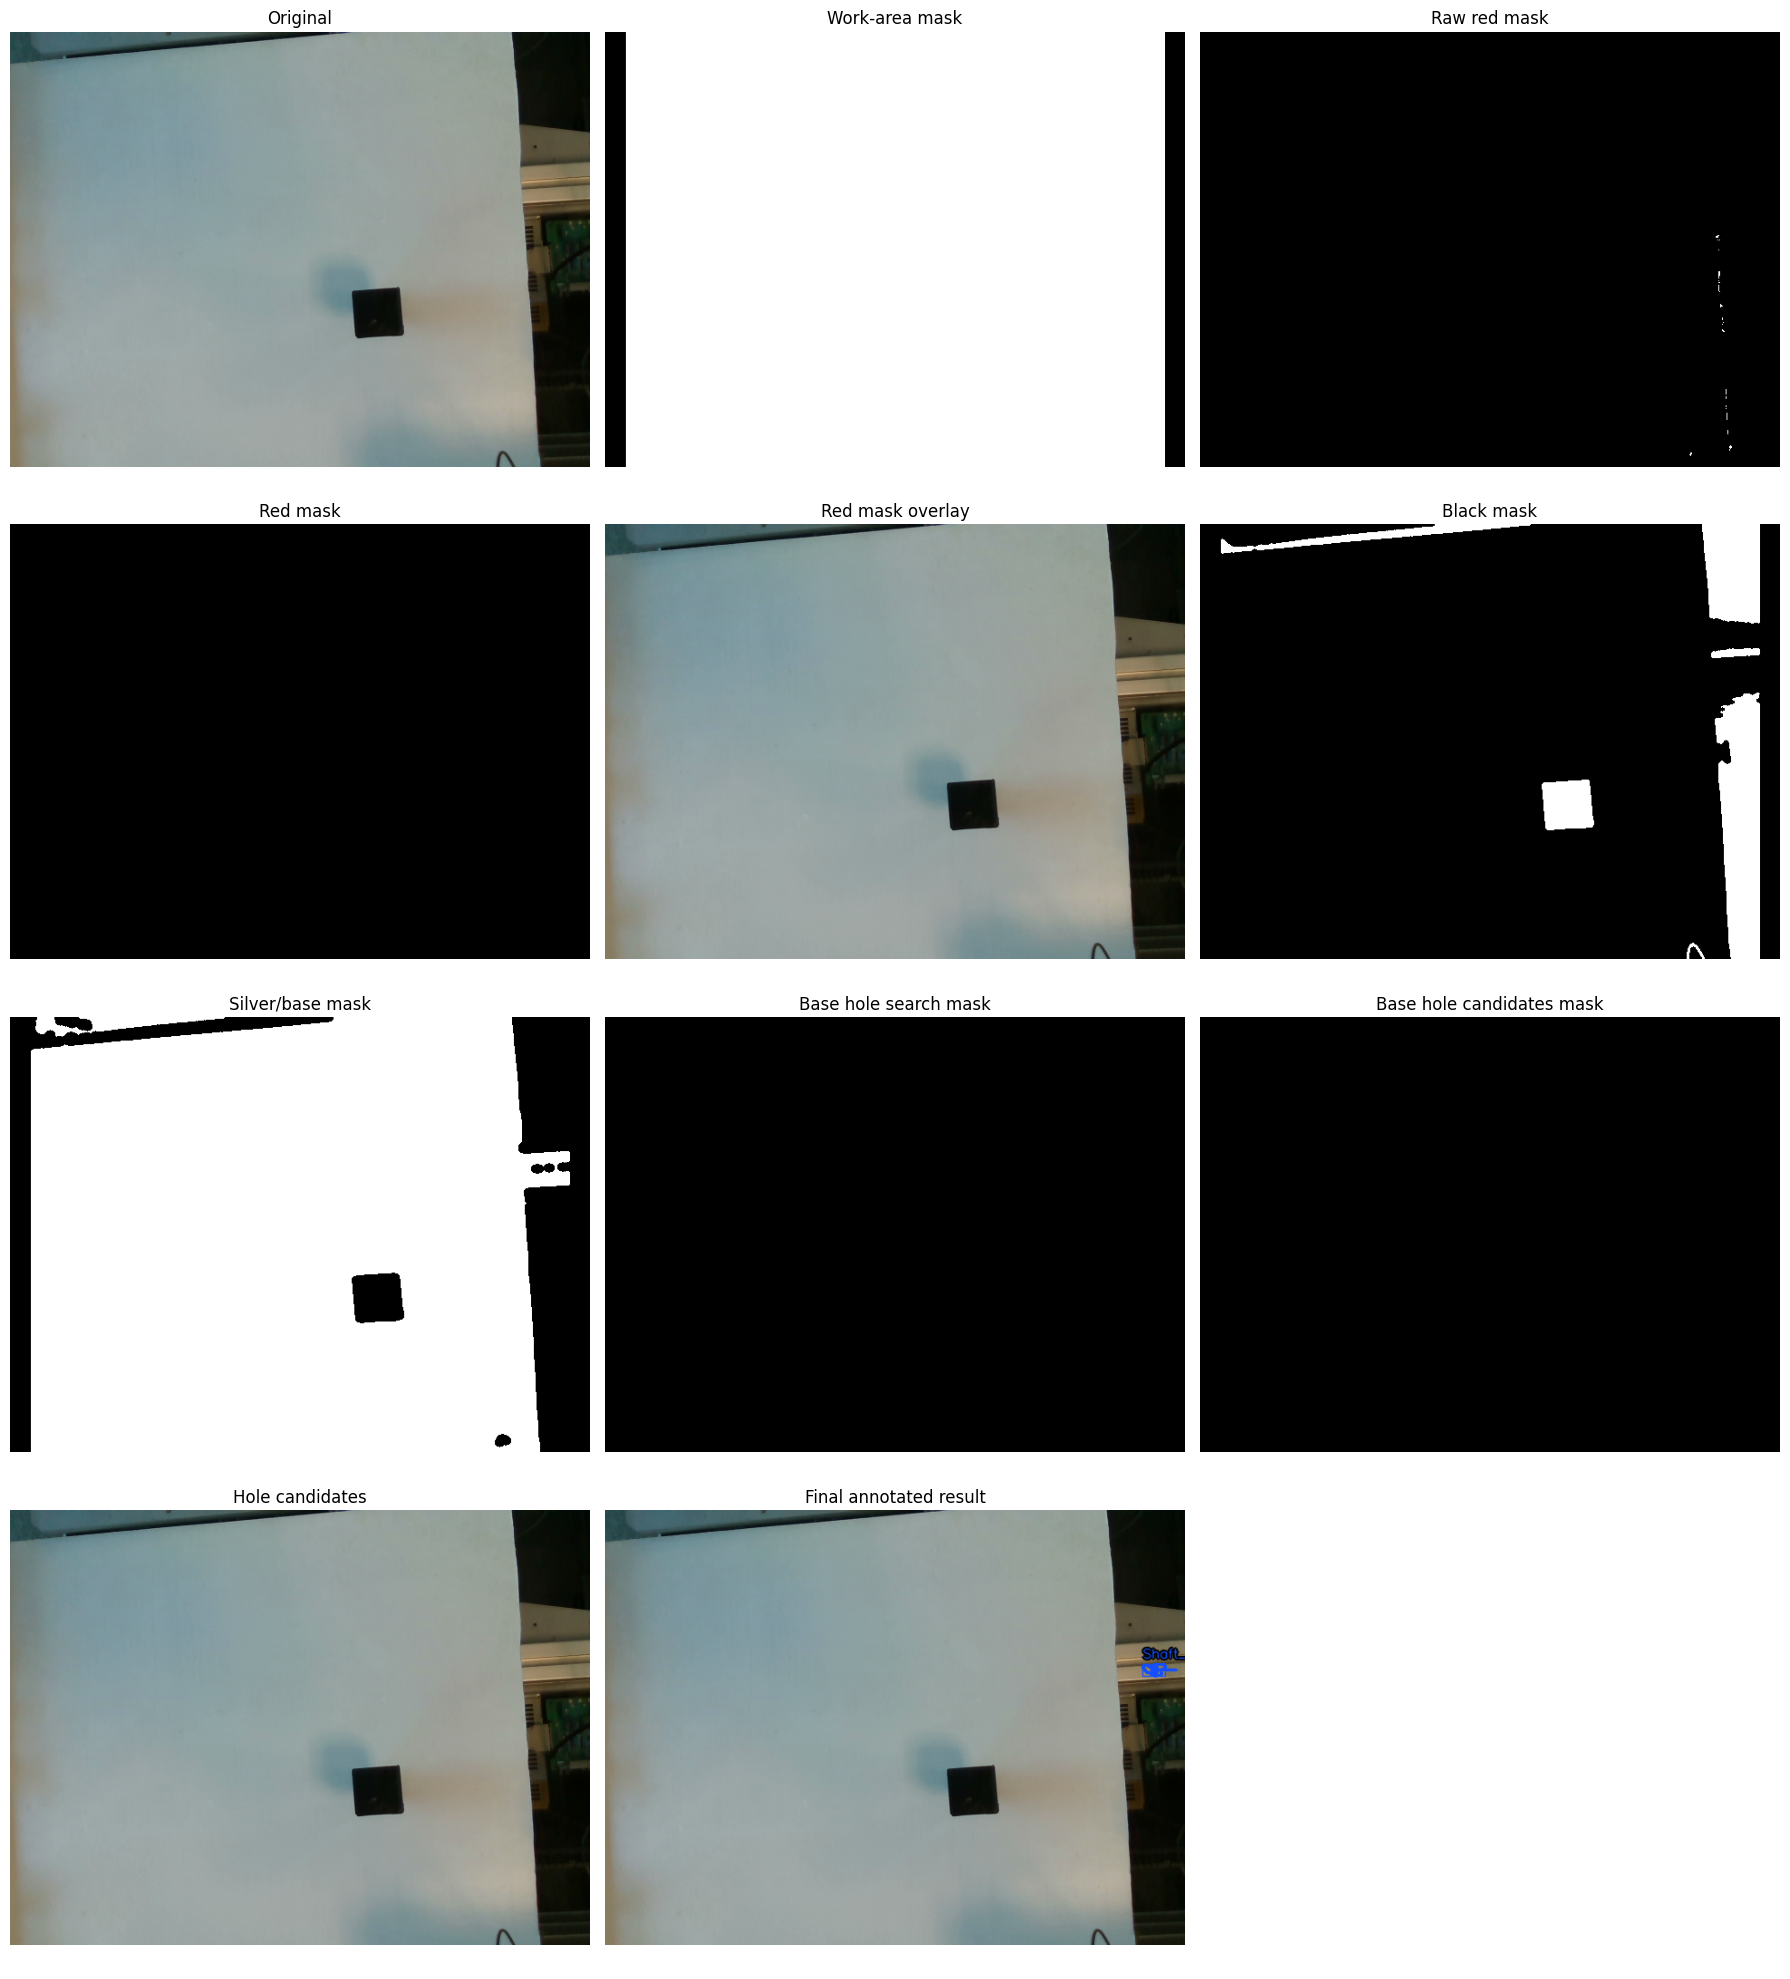


Detection summary:
  Shaft_large    center=(606.2, 175.5) confidence=medium type_certain=False

NEW annotated image: /home/jingyun/Xinyu/ais_hiwi/output/global_detection/global_detection_result_black_holes.png
NEW debug image:     /home/jingyun/Xinyu/ais_hiwi/output/global_detection/global_detection_debug_black_holes.png
Saved CSV:           /home/jingyun/Xinyu/ais_hiwi/output/global_detection/global_detection_results.csv
Saved JSON:          /home/jingyun/Xinyu/ais_hiwi/output/global_detection/global_detection_results.json


In [10]:
print("Detector version: black-top-screw and perspective-hole v4")
DETECTION_RESULTS, DEBUG_IMAGES = main()


## Result summary

In [11]:
summary_fields = [
    "class_name", "center_u", "center_v", "bbox_x", "bbox_y",
    "bbox_w", "bbox_h", "area_px", "yaw_deg", "confidence", "rule_note",
    "type_certain", "classification_status", "classification_reason",
]
[
    {key: result.get(key) for key in summary_fields}
    for result in DETECTION_RESULTS
]


[{'class_name': 'Shaft_large',
  'center_u': 606.16,
  'center_v': 175.52,
  'bbox_x': 593,
  'bbox_y': 170,
  'bbox_w': 26,
  'bbox_h': 14,
  'area_px': 200.0,
  'yaw_deg': 0.0,
  'confidence': 'medium',
  'rule_note': 'only one shaft candidate detected; large label is provisional; white rectangular component with smaller rotated area; relaxed white-shaft fallback candidate; shaft_score=3.97, rectangularity=0.62, aspect=1.92',
  'type_certain': False,
  'classification_status': 'uncertain',
  'classification_reason': 'shaft set incomplete or large/small rotated-area separation below 8%'}]

In [12]:
# RealSense D435i live RGB global-detection viewer.
# Run this cell after all detection-function cells above have been executed.

import time
import numpy as np
import cv2


def detect_live_frame_bgr(color_bgr):
    """Run the existing notebook detection pipeline without saving anything."""
    work_mask = create_work_area_mask(color_bgr)
    red_mask, red_mask_raw, red_mask_debug_overlay = segment_red_objects(
        color_bgr, work_mask, return_debug=True
    )
    black_mask = segment_black_objects(color_bgr, work_mask)
    white_shaft_mask = segment_white_shafts(color_bgr, work_mask)
    base_mask = segment_silver_base(
        color_bgr, work_mask, red_mask, black_mask
    )

    red_results = detect_red_parts(
        color_bgr, red_mask, screw_reject_mask=white_shaft_mask
    )
    base_results = detect_silver_base(color_bgr, base_mask, warn=False)
    # Base holes and their shadows also appear in the global black mask.
    # Remove the full detected base ROI only for shaft classification; hole
    # detection below still receives the unmodified black_mask.
    shaft_white_mask = white_shaft_mask.copy()
    # Category-exclusion only: red objects and the detected base are not shafts.
    # This does not assume any fixed part layout. Fill red object contours so
    # white highlights inside red gears are excluded as part of the red object.
    red_object_exclusion_mask = np.zeros_like(shaft_white_mask)
    red_object_contours, _ = cv2.findContours(
        red_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    if red_object_contours:
        cv2.drawContours(
            red_object_exclusion_mask, red_object_contours,
            -1, 255, thickness=-1,
        )
        red_object_exclusion_mask = cv2.dilate(
            red_object_exclusion_mask, _odd_kernel(15)
        )
        shaft_white_mask[red_object_exclusion_mask > 0] = 0
    if base_results:
        base_exclusion_mask = np.zeros_like(white_shaft_mask)
        cv2.drawContours(
            base_exclusion_mask, [base_results[0]["_contour"]],
            -1, 255, thickness=-1,
        )
        base_exclusion_mask = cv2.dilate(base_exclusion_mask, _odd_kernel(3))
        shaft_white_mask[base_exclusion_mask > 0] = 0
    shaft_results = detect_white_shafts(color_bgr, shaft_white_mask)

    hole_results = []
    hole_search_mask = np.zeros(color_bgr.shape[:2], dtype=np.uint8)
    hole_candidates_mask = np.zeros(color_bgr.shape[:2], dtype=np.uint8)
    hole_candidate_debug = color_bgr.copy()
    if base_results:
        (
            hole_results,
            hole_search_mask,
            hole_candidates_mask,
            hole_candidate_debug,
        ) = detect_base_insert_holes_from_black_mask(
            color_bgr, base_results[0]["_contour"], black_mask
        )

    results = red_results + shaft_results + base_results + hole_results
    annotated = draw_results(color_bgr, results)
    debug_views = {
        "annotated": annotated,
        "red_mask_raw": red_mask_raw,
        "red_mask": red_mask,
        "red_mask_debug_overlay": red_mask_debug_overlay,
        "black_mask": black_mask,
        "shaft_white_mask": shaft_white_mask,
        "base_mask": base_mask,
        "base_hole_search_mask": hole_search_mask,
        "base_hole_candidates_mask": hole_candidates_mask,
        "hole_candidate_debug": hole_candidate_debug,
    }
    return annotated, results, debug_views


def run_realsense_global_detection_live():
    """Open RealSense live view and keep the last frame as DETECTION_RESULTS.

    After quitting with q/ESC, downstream cells use the final live frame instead
    of the offline IMAGE_PATH result.
    """
    try:
        import pyrealsense2 as rs
    except ImportError:
        print(
            "pyrealsense2 is not installed. Install the RealSense Python "
            "package before running this cell."
        )
        return

    window_name = "RealSense Global Detection Live"
    pipeline = rs.pipeline()
    config = rs.config()
    config.enable_stream(
        rs.stream.color, 640, 480, rs.format.bgr8, 30
    )

    pipeline_started = False
    previous_gray = None
    stable_frame_count = 0
    paused = False
    display_mode_index = 0
    last_display = None
    last_results = []
    last_color_bgr = None
    last_annotated = None
    last_debug_views = None
    last_motion_score = 0.0
    last_state = "MOVING"
    fps = 0.0
    previous_time = None
    last_frame_timestamp_sec = None

    previous_results_source = globals().get("DETECTION_RESULTS_SOURCE")
    globals()["DETECTION_RESULTS_SOURCE"] = "RealSense live viewer started; no live frame processed yet"

    try:
        try:
            profile = pipeline.start(config)
            device = profile.get_device()
            color_sensor = None
            for sensor in device.query_sensors():
                sensor_name = sensor.get_info(rs.camera_info.name)
                if "RGB" in sensor_name or "Color" in sensor_name:
                    color_sensor = sensor
                    break
            if color_sensor is not None:
                # Previous live-view camera settings kept for reference:
                # if color_sensor.supports(rs.option.power_line_frequency):
                #     color_sensor.set_option(rs.option.power_line_frequency, 1)
                # if color_sensor.supports(rs.option.brightness):
                #     color_sensor.set_option(rs.option.brightness, -40)

                GLOBAL_FIXED_RGB_SETTINGS = {
                    "enable_auto_exposure": False,
                    "auto_exposure_priority": 0,
                    "power_line_frequency": 1,
                    "exposure": 260,
                    "gain": 96,
                    "enable_auto_white_balance": False,
                    "white_balance": 3600,
                    "brightness": 0,
                    "contrast": 45,
                    "saturation": 58,
                    "sharpness": 35,
                    "gamma": 300,
                }

                def _set_color_option_safe(option_attr, value):
                    if not hasattr(rs.option, option_attr):
                        print(f"RGB {option_attr}: option enum not available")
                        return None
                    option = getattr(rs.option, option_attr)
                    try:
                        if not color_sensor.supports(option):
                            print(f"RGB {option_attr}: not supported")
                            return None
                        color_sensor.set_option(option, float(value))
                        actual = color_sensor.get_option(option)
                        print(f"RGB {option_attr}: set to {actual}")
                        return actual
                    except Exception as option_exc:
                        print(f"RGB {option_attr}: failed to set {value}: {option_exc}")
                        return None

                print("Applying fixed global RGB camera settings")
                for option_attr, value in GLOBAL_FIXED_RGB_SETTINGS.items():
                    _set_color_option_safe(option_attr, value)
                
            pipeline_started = True
        except Exception as exc:
            print(
                "Could not start RealSense D435i. Check that the camera is "
                f"connected and not used by another process. Details: {exc}"
            )
            return

        print(
            "Live controls: q/ESC quit, space pause/resume, "
            "d cycle debug views."
        )
        try:
            cv2.startWindowThread()
        except Exception:
            pass
        try:
            cv2.namedWindow(window_name, cv2.WINDOW_NORMAL)
        except Exception as exc:
            print(
                "Could not create OpenCV display window. If you are running over SSH "
                "or inside a headless VSCode/Jupyter session, run the notebook on the "
                f"machine display or enable X forwarding. Details: {exc}"
            )
            return

        while True:
            if not paused:
                frames = pipeline.wait_for_frames(timeout_ms=5000)
                color_frame = frames.get_color_frame()
                if not color_frame:
                    print("No RealSense color frame received; retrying.")
                    continue

                color_bgr = np.asanyarray(color_frame.get_data())
                if color_bgr is None or color_bgr.size == 0:
                    print("Received an empty RealSense color frame; retrying.")
                    continue
                annotated, results, debug_views = detect_live_frame_bgr(
                    color_bgr
                )

                gray = cv2.cvtColor(color_bgr, cv2.COLOR_BGR2GRAY)
                if previous_gray is None:
                    motion_score = 0.0
                    stable_frame_count = 0
                else:
                    motion_score = float(
                        cv2.mean(cv2.absdiff(gray, previous_gray))[0]
                    )
                    stable_frame_count = (
                        stable_frame_count + 1
                        if motion_score < 2.0
                        else 0
                    )
                previous_gray = gray
                state = "STABLE" if stable_frame_count >= 10 else "MOVING"

                now = time.perf_counter()
                if previous_time is not None:
                    instant_fps = 1.0 / max(now - previous_time, 1e-6)
                    fps = (
                        instant_fps
                        if fps <= 0.0
                        else 0.85 * fps + 0.15 * instant_fps
                    )
                previous_time = now

                available_modes = [
                    name
                    for name in (
                        "annotated",
                        "red_mask_raw",
                        "red_mask",
                        "red_mask_debug_overlay",
                        "black_mask",
                        "shaft_white_mask",
                        "base_mask",
                        "base_hole_search_mask",
                        "base_hole_candidates_mask",
                        "hole_candidate_debug",
                    )
                    if name in debug_views
                    and debug_views[name] is not None
                    and np.asarray(debug_views[name]).size > 0
                ]
                if not available_modes:
                    available_modes = ["annotated"]
                    debug_views["annotated"] = annotated
                display_mode_index %= len(available_modes)
                mode_name = available_modes[display_mode_index]
                view = debug_views[mode_name]
                if view.ndim == 2:
                    view = cv2.cvtColor(view, cv2.COLOR_GRAY2BGR)
                else:
                    view = view.copy()

                status_color = (
                    (40, 220, 40) if state == "STABLE" else (0, 165, 255)
                )
                cv2.putText(
                    view,
                    (
                        f"FPS {fps:5.1f}  num_results {len(results)}  "
                        f"{state}  motion_score {motion_score:.2f}"
                    ),
                    (10, 24),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.55,
                    (0, 0, 0),
                    3,
                    cv2.LINE_AA,
                )
                cv2.putText(
                    view,
                    (
                        f"FPS {fps:5.1f}  num_results {len(results)}  "
                        f"{state}  motion_score {motion_score:.2f}"
                    ),
                    (10, 24),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.55,
                    status_color,
                    1,
                    cv2.LINE_AA,
                )
                cv2.putText(
                    view,
                    f"view: {mode_name}",
                    (10, 47),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.5,
                    (255, 255, 255),
                    1,
                    cv2.LINE_AA,
                )
                last_display = view
                last_results = results
                last_color_bgr = color_bgr.copy()
                last_annotated = annotated.copy()
                last_debug_views = {
                    name: image.copy() if isinstance(image, np.ndarray) else image
                    for name, image in debug_views.items()
                }
                last_motion_score = motion_score
                last_state = state
                last_frame_timestamp_sec = time.time()

                # Make the current live frame the notebook-wide latest result.
                # Cells below that read DETECTION_RESULTS will now use this live
                # frame instead of the offline IMAGE_PATH result.
                globals()["DETECTION_RESULTS"] = results
                globals()["DEBUG_IMAGES"] = debug_views
                globals()["LAST_LIVE_DETECTION_RESULTS"] = results
                globals()["LAST_LIVE_COLOR_BGR"] = color_bgr.copy()
                globals()["LAST_LIVE_ANNOTATED"] = annotated.copy()
                globals()["LAST_LIVE_DEBUG_VIEWS"] = debug_views
                globals()["LAST_LIVE_TIMESTAMP_SEC"] = last_frame_timestamp_sec
                globals()["DETECTION_RESULTS_SOURCE"] = "last RealSense live frame"
            elif last_display is not None:
                view = last_display.copy()
                cv2.putText(
                    view,
                    "PAUSED",
                    (10, 72),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.65,
                    (0, 0, 255),
                    2,
                    cv2.LINE_AA,
                )
                last_display = view

            if last_display is not None:
                cv2.imshow(window_name, last_display)

            key = cv2.waitKey(1 if not paused else 30) & 0xFF
            if key in (ord("q"), 27):
                break
            if key == ord(" "):
                paused = not paused
                print("Live view paused." if paused else "Live view resumed.")
            elif key == ord("d"):
                display_mode_index += 1
                print("Debug view changed.")

    except KeyboardInterrupt:
        print("Live detection interrupted.")
    except Exception as exc:
        print(f"RealSense live detection stopped after an error: {exc}")
    finally:
        if pipeline_started:
            pipeline.stop()
        cv2.destroyAllWindows()
        if last_annotated is not None:
            # Commit exactly the final processed live frame. If the view was
            # paused before quitting, this is the frozen frame. IMAGE_PATH is
            # not read anywhere in this live path.
            globals()["DETECTION_RESULTS"] = last_results
            globals()["DEBUG_IMAGES"] = last_debug_views
            globals()["LAST_LIVE_DETECTION_RESULTS"] = last_results
            globals()["LAST_LIVE_COLOR_BGR"] = last_color_bgr
            globals()["LAST_LIVE_ANNOTATED"] = last_annotated
            globals()["LAST_LIVE_DEBUG_VIEWS"] = last_debug_views
            globals()["LAST_LIVE_TIMESTAMP_SEC"] = last_frame_timestamp_sec
            globals()["LAST_LIVE_FRAME_AVAILABLE"] = True
            globals()["DETECTION_RESULTS_SOURCE"] = (
                "final paused RealSense live frame"
                if paused else "final RealSense live frame"
            )
            names = [
                item.get("hole_name") or item.get("instance_name") or item.get("class_name")
                for item in last_results
            ]
            print(
                "Final live frame stored in DETECTION_RESULTS: "
                f"{len(last_results)} detections -> {names}"
            )
        else:
            globals()["LAST_LIVE_FRAME_AVAILABLE"] = False
            if previous_results_source is not None:
                globals()["DETECTION_RESULTS_SOURCE"] = previous_results_source
            print("No RealSense live frame was processed; existing results were not overwritten.")
        print("RealSense live detection closed.")

    return last_results if last_annotated is not None else None


FINAL_LIVE_DETECTION_RESULTS = run_realsense_global_detection_live()
if FINAL_LIVE_DETECTION_RESULTS is not None:
    # Persist and display the same final live frame committed above.
    save_results_csv(FINAL_LIVE_DETECTION_RESULTS, CSV_PATH)
    save_results_json(FINAL_LIVE_DETECTION_RESULTS, JSON_PATH)
    if LAST_LIVE_ANNOTATED is not None:
        cv2.imwrite(str(ANNOTATED_PATH), LAST_LIVE_ANNOTATED)
    if LAST_LIVE_COLOR_BGR is not None:
        cv2.imwrite(
            str(OUTPUT_DIR / "global_detection_last_live_color.png"),
            LAST_LIVE_COLOR_BGR,
        )
    for debug_name, debug_image in (LAST_LIVE_DEBUG_VIEWS or {}).items():
        if isinstance(debug_image, np.ndarray) and debug_image.ndim in (2, 3):
            cv2.imwrite(
                str(OUTPUT_DIR / f"global_detection_last_live_{debug_name}.png"),
                debug_image,
            )
    FINAL_LIVE_RESULT_SUMMARY = [
        _public_result(item) for item in FINAL_LIVE_DETECTION_RESULTS
    ]
    print("Detection results source:", DETECTION_RESULTS_SOURCE)
    _print_detection_summary(FINAL_LIVE_DETECTION_RESULTS)
    print("Final live JSON:", JSON_PATH)
    print("Final live CSV:", CSV_PATH)
else:
    FINAL_LIVE_RESULT_SUMMARY = []

FINAL_LIVE_RESULT_SUMMARY


Applying fixed global RGB camera settings
RGB enable_auto_exposure: set to 0.0
RGB auto_exposure_priority: set to 0.0
RGB power_line_frequency: set to 1.0
RGB exposure: set to 260.0
RGB gain: set to 96.0
RGB enable_auto_white_balance: set to 0.0
RGB white_balance: set to 3600.0
RGB brightness: set to 0.0
RGB contrast: set to 45.0
RGB saturation: set to 58.0
RGB sharpness: set to 35.0
RGB gamma: set to 300.0
Live controls: q/ESC quit, space pause/resume, d cycle debug views.


QFontDatabase: Cannot find font directory /home/jingyun/anaconda3/envs/xinyu_zhuo/lib/python3.10/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to fontconfig.
QFontDatabase: Cannot find font directory /home/jingyun/anaconda3/envs/xinyu_zhuo/lib/python3.10/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to fontconfig.
QFontDatabase: Cannot find font directory /home/jingyun/anaconda3/envs/xinyu_zhuo/lib/python3.10/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to fontconfig.
QFontDatabase: Cannot find font directory /home/jingyun/anaconda3/envs/xinyu_zhuo/lib/python3.10/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to fontconfig.
QFon

Final live frame stored in DETECTION_RESULTS: 2 detections -> ['Gear_compound', 'Base']
RealSense live detection closed.
Detection results source: final RealSense live frame

Detection summary:
  Gear_compound  center=(590.5, 195.2) confidence=medium type_certain=False
  Base           center=(118.0, 260.2) confidence=high type_certain=True
Final live JSON: /home/jingyun/Xinyu/ais_hiwi/output/global_detection/global_detection_results.json
Final live CSV: /home/jingyun/Xinyu/ais_hiwi/output/global_detection/global_detection_results.csv


[{'class_name': 'Gear_compound',
  'center_u': 590.52,
  'center_v': 195.22,
  'bbox_x': 546,
  'bbox_y': 99,
  'bbox_w': 72,
  'bbox_h': 190,
  'area_px': 8936.5,
  'yaw_deg': -90.0,
  'confidence': 'medium',
  'rule_note': 'large gear-like contour; compound structure inferred by size and few through-holes',
  'type_certain': False,
  'classification_status': 'uncertain',
  'classification_reason': 'only 1 of 3 expected gear candidates detected; class_name is an absolute-geometry best guess',
  'classification_set_complete': False,
  'shaft_size_margin_ratio': None,
  'gear_outer_radius_px': 94.69,
  'gear_inner_square_center': None,
  'grasp_hint_2d': [590.52, 195.22],
  'rect_width_px': None,
  'rect_height_px': None,
  'long_side_px': None,
  'short_side_px': None,
  'edge_midpoints_2d': None,
  'grasp_candidates_2d': None,
  'base_contour_area': None,
  'base_rotated_rect': None,
  'base_hole_candidates_2d': None,
  'base_insert_holes_2d': None,
  'hole_name': None,
  'hole_radius

In [13]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from global_table_intersection_utils import (
    add_camera_table_intersection_to_detections,
    load_hand_eye_npz,
    pixel_to_table_intersection_camera,
)

HAND_EYE_NPZ_PATH = Path("cam_calibration/outputs/03_hand_eye/hand_eye_result.npz")
TABLE_Z_M = 0.0
CAMERA_FRAME_ID = "camera_color_optical_frame"
DEFAULT_CSV_PATH = Path("output/global_detection/global_detection_results.csv")
DEFAULT_JSON_PATH = Path("output/global_detection/global_detection_results.json")

csv_output_path = Path(globals().get("CSV_PATH", DEFAULT_CSV_PATH))
json_output_path = Path(globals().get("JSON_PATH", DEFAULT_JSON_PATH))

def _result_count(results):
    return len(results) if isinstance(results, list) else 0


def _select_latest_detection_results(json_output_path: Path):
    candidates = [
        ("FINAL_LIVE_DETECTION_RESULTS", globals().get("FINAL_LIVE_DETECTION_RESULTS")),
        ("LAST_LIVE_DETECTION_RESULTS", globals().get("LAST_LIVE_DETECTION_RESULTS")),
        ("DETECTION_RESULTS", globals().get("DETECTION_RESULTS")),
    ]
    candidates = [(name, value) for name, value in candidates if isinstance(value, list) and value]
    if candidates:
        live_candidates = [item for item in candidates if "LIVE" in item[0]]
        if live_candidates:
            name, value = max(live_candidates, key=lambda item: _result_count(item[1]))
        else:
            name, value = candidates[0]
        source = globals().get("DETECTION_RESULTS_SOURCE", name)
        return value, source, name
    if json_output_path.exists():
        value = json.loads(json_output_path.read_text(encoding="utf-8"))
        return value, str(json_output_path), "global_detection_results.json"
    raise FileNotFoundError(
        "没有找到可用的检测结果。请先运行 RealSense live cell，或确认已有 global_detection_results.json。"
    )

detection_results_input, detection_results_source, detection_results_variable = _select_latest_detection_results(
    json_output_path
)
print(
    f"Using {len(detection_results_input)} detections from {detection_results_variable}: "
    f"{detection_results_source}"
)
if (
    detection_results_variable == "DETECTION_RESULTS"
    and isinstance(globals().get("LAST_LIVE_DETECTION_RESULTS"), list)
    and len(globals()["LAST_LIVE_DETECTION_RESULTS"]) > len(detection_results_input)
):
    print(
        "Warning: DETECTION_RESULTS has fewer items than LAST_LIVE_DETECTION_RESULTS; "
        "restart/rerun the live cell or rerun this coordinate cell."
    )




def _json_safe(value):
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, np.floating):
        return float(value)
    if isinstance(value, np.bool_):
        return bool(value)
    if isinstance(value, dict):
        return {
            str(key): _json_safe(val)
            for key, val in value.items()
            if not str(key).startswith("_")
        }
    if isinstance(value, (list, tuple)):
        return [_json_safe(item) for item in value]
    return value


def _public_augmented_result(item):
    return {
        str(key): _json_safe(value)
        for key, value in item.items()
        if not str(key).startswith("_")
    }

def _save_augmented_results(results, csv_path, json_path):
    csv_path = Path(csv_path)
    json_path = Path(json_path)
    csv_path.parent.mkdir(parents=True, exist_ok=True)
    json_path.parent.mkdir(parents=True, exist_ok=True)

    safe_results = [_public_augmented_result(item) for item in results]
    csv_rows = []
    for item in safe_results:
        row = {}
        for key, value in item.items():
            if isinstance(value, (list, dict)):
                row[key] = json.dumps(value, ensure_ascii=False)
            else:
                row[key] = value
        csv_rows.append(row)

    pd.DataFrame(csv_rows).to_csv(csv_path, index=False, encoding="utf-8-sig")
    json_path.write_text(
        json.dumps(safe_results, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )


def _global_camera_coordinate_rows(results):
    rows = []
    for idx, item in enumerate(results):
        point_name = item.get("hole_name") or item.get("instance_name") or item.get("class_name") or f"point_{idx}"
        role = "base_hole" if item.get("hole_name") else "part_center"
        rows.append({
            "point_name": point_name,
            "role": role,
            "class_name": item.get("class_name"),
            "u_px": item.get("center_u"),
            "v_px": item.get("center_v"),
            "depth_valid": item.get("depth_valid"),
            "depth_m": item.get("depth_m"),
            "camera_x_m": item.get("camera_x_m"),
            "camera_y_m": item.get("camera_y_m"),
            "camera_z_m": item.get("camera_z_m"),
            "camera_frame_id": item.get("camera_frame_id"),
            "source": item.get("depth_source") or item.get("used_depth_source"),
            "reason": item.get("ray_table_intersection_reason"),
        })
    return rows

# Camera-frame table-intersection still needs the current robot pose because
# the table plane is defined in robot base frame as base_z = TABLE_Z_M.
# This identity pose is only for code/display testing. Replace it with the real
# Franka T_base_gripper for geometrically meaningful numbers.
T_base_gripper_global_observation = np.eye(4, dtype=np.float64)

T_gripper_camera_npz, CAMERA_MATRIX_NPZ, DIST_COEFFS_NPZ = load_hand_eye_npz(
    HAND_EYE_NPZ_PATH
)

example_intersection = pixel_to_table_intersection_camera(
    u=320.0,
    v=240.0,
    K=CAMERA_MATRIX_NPZ,
    T_base_gripper=T_base_gripper_global_observation,
    T_gripper_camera=T_gripper_camera_npz,
    z_table=TABLE_Z_M,
    camera_frame_id=CAMERA_FRAME_ID,
)
print("Detection results source:", detection_results_source)
print("Camera-frame table-intersection example using placeholder T_base_gripper (for smoke test only):")
for key in (
    "center_px",
    "camera_x_m",
    "camera_y_m",
    "camera_z_m",
    "camera_frame_id",
    "depth_valid",
    "ray_table_intersection_reason",
):
    print(f"  {key}: {example_intersection[key]}")

DETECTION_RESULTS_CAMERA_TABLE_OFFLINE = add_camera_table_intersection_to_detections(
    detection_results_input,
    CAMERA_MATRIX_NPZ,
    T_base_gripper_global_observation,
    T_gripper_camera_npz,
    TABLE_Z_M,
    camera_frame_id=CAMERA_FRAME_ID,
)

_save_augmented_results(
    DETECTION_RESULTS_CAMERA_TABLE_OFFLINE,
    csv_output_path,
    json_output_path,
)

print("\nGlobal detection camera-frame coordinates")
print("Source:", detection_results_source)
print("Frame:", CAMERA_FRAME_ID)
print("Note: these are RGB ray/table-intersection coordinates. With the placeholder pose, camera_x/y/z may be None; use the manual/real-pose cell for meaningful coordinates.")
global_camera_df = pd.DataFrame(_global_camera_coordinate_rows(DETECTION_RESULTS_CAMERA_TABLE_OFFLINE))
display(global_camera_df)
if {"point_name", "class_name"}.issubset(global_camera_df.columns):
    shaft_large_rows = global_camera_df[
        global_camera_df["point_name"].astype(str).str.lower().str.contains("shaft_large", na=False)
        | global_camera_df["class_name"].astype(str).str.lower().str.contains("shaft_large", na=False)
    ]
    if not shaft_large_rows.empty:
        print("\nshaft_large camera-frame coordinate row:")
        display(shaft_large_rows)
print("Saved augmented CSV:", csv_output_path)
print("Saved augmented JSON:", json_output_path)


Using 2 detections from FINAL_LIVE_DETECTION_RESULTS: final RealSense live frame
Detection results source: final RealSense live frame
Camera-frame table-intersection example using placeholder T_base_gripper (for smoke test only):
  center_px: [320.0, 240.0]
  camera_x_m: None
  camera_y_m: None
  camera_z_m: None
  camera_frame_id: camera_color_optical_frame
  depth_valid: False
  ray_table_intersection_reason: table intersection lies behind the camera

Global detection camera-frame coordinates
Source: final RealSense live frame
Frame: camera_color_optical_frame
Note: these are RGB ray/table-intersection coordinates. With the placeholder pose, camera_x/y/z may be None; use the manual/real-pose cell for meaningful coordinates.


,point_name,role,class_name,u_px,v_px,depth_valid,depth_m,camera_x_m,camera_y_m,camera_z_m,camera_frame_id,source,reason
0,Gear_compound,part_center,Gear_compound,590.52,195.22,False,None,None,None,None,camera_color_optical_frame,rgb_ray_table_intersection,table intersection lies behind the camera
1,Base,part_center,Base,117.96,260.23,False,None,None,None,None,camera_color_optical_frame,rgb_ray_table_intersection,table intersection lies behind the camera


Saved augmented CSV: /home/jingyun/Xinyu/ais_hiwi/output/global_detection/global_detection_results.csv
Saved augmented JSON: /home/jingyun/Xinyu/ais_hiwi/output/global_detection/global_detection_results.json


In [14]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from global_table_intersection_utils import add_camera_table_intersection_to_detections, load_hand_eye_npz

HAND_EYE_NPZ_PATH = Path("cam_calibration/outputs/03_hand_eye/hand_eye_result.npz")
TABLE_Z_M = 0.0
CAMERA_FRAME_ID = "camera_color_optical_frame"
DEFAULT_CSV_PATH = Path("output/global_detection/global_detection_results.csv")
DEFAULT_JSON_PATH = Path("output/global_detection/global_detection_results.json")

csv_output_path = Path(globals().get("CSV_PATH", DEFAULT_CSV_PATH))
json_output_path = Path(globals().get("JSON_PATH", DEFAULT_JSON_PATH))

def _result_count(results):
    return len(results) if isinstance(results, list) else 0


def _select_latest_detection_results(json_output_path: Path):
    candidates = [
        ("FINAL_LIVE_DETECTION_RESULTS", globals().get("FINAL_LIVE_DETECTION_RESULTS")),
        ("LAST_LIVE_DETECTION_RESULTS", globals().get("LAST_LIVE_DETECTION_RESULTS")),
        ("DETECTION_RESULTS", globals().get("DETECTION_RESULTS")),
    ]
    candidates = [(name, value) for name, value in candidates if isinstance(value, list) and value]
    if candidates:
        live_candidates = [item for item in candidates if "LIVE" in item[0]]
        if live_candidates:
            name, value = max(live_candidates, key=lambda item: _result_count(item[1]))
        else:
            name, value = candidates[0]
        source = globals().get("DETECTION_RESULTS_SOURCE", name)
        return value, source, name
    if json_output_path.exists():
        value = json.loads(json_output_path.read_text(encoding="utf-8"))
        return value, str(json_output_path), "global_detection_results.json"
    raise FileNotFoundError(
        "没有找到可用的检测结果。请先运行 RealSense live cell，或确认已有 global_detection_results.json。"
    )

detection_results_input, detection_results_source, detection_results_variable = _select_latest_detection_results(
    json_output_path
)
print(
    f"Using {len(detection_results_input)} detections from {detection_results_variable}: "
    f"{detection_results_source}"
)
if (
    detection_results_variable == "DETECTION_RESULTS"
    and isinstance(globals().get("LAST_LIVE_DETECTION_RESULTS"), list)
    and len(globals()["LAST_LIVE_DETECTION_RESULTS"]) > len(detection_results_input)
):
    print(
        "Warning: DETECTION_RESULTS has fewer items than LAST_LIVE_DETECTION_RESULTS; "
        "restart/rerun the live cell or rerun this coordinate cell."
    )




def _json_safe(value):
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, np.floating):
        return float(value)
    if isinstance(value, np.bool_):
        return bool(value)
    if isinstance(value, dict):
        return {
            str(key): _json_safe(val)
            for key, val in value.items()
            if not str(key).startswith("_")
        }
    if isinstance(value, (list, tuple)):
        return [_json_safe(item) for item in value]
    return value


def _public_augmented_result(item):
    return {
        str(key): _json_safe(value)
        for key, value in item.items()
        if not str(key).startswith("_")
    }

def _save_augmented_results(results, csv_path, json_path):
    csv_path = Path(csv_path)
    json_path = Path(json_path)
    csv_path.parent.mkdir(parents=True, exist_ok=True)
    json_path.parent.mkdir(parents=True, exist_ok=True)

    safe_results = [_public_augmented_result(item) for item in results]
    csv_rows = []
    for item in safe_results:
        row = {}
        for key, value in item.items():
            if isinstance(value, (list, dict)):
                row[key] = json.dumps(value, ensure_ascii=False)
            else:
                row[key] = value
        csv_rows.append(row)

    pd.DataFrame(csv_rows).to_csv(csv_path, index=False, encoding="utf-8-sig")
    json_path.write_text(
        json.dumps(safe_results, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )

def _global_camera_coordinate_rows(results):
    rows = []
    for idx, item in enumerate(results):
        point_name = item.get("hole_name") or item.get("instance_name") or item.get("class_name") or f"point_{idx}"
        role = "base_hole" if item.get("hole_name") else "part_center"
        rows.append({
            "point_name": point_name,
            "role": role,
            "class_name": item.get("class_name"),
            "u_px": item.get("center_u"),
            "v_px": item.get("center_v"),
            "depth_valid": item.get("depth_valid"),
            "depth_m": item.get("depth_m"),
            "camera_x_m": item.get("camera_x_m"),
            "camera_y_m": item.get("camera_y_m"),
            "camera_z_m": item.get("camera_z_m"),
            "camera_frame_id": item.get("camera_frame_id"),
            "source": item.get("depth_source") or item.get("used_depth_source"),
            "reason": item.get("ray_table_intersection_reason"),
        })
    return rows

T_gripper_camera_npz, CAMERA_MATRIX_NPZ, DIST_COEFFS_NPZ = load_hand_eye_npz(
    HAND_EYE_NPZ_PATH
)

# Paste the real Franka current T_base_gripper here for the same global observation frame.
# Even though the output below is camera-frame only, this pose is still required because
# the table plane is defined in robot base frame as base_z = TABLE_Z_M.
T_base_gripper_manual = np.array([
    [0.975988289, -0.197100409,  0.092726956, 0.421137814],
    [-0.187685331, -0.976997512, -0.101242664, 0.003140927],
    [0.110548975,  0.081408166, -0.990530986, 0.715974466],
    [0.000000000,  0.000000000,  0.000000000, 1.000000000],
], dtype=np.float64)

DETECTION_RESULTS_CAMERA_TABLE_MANUAL = add_camera_table_intersection_to_detections(
    detection_results_input,
    CAMERA_MATRIX_NPZ,
    T_base_gripper_manual,
    T_gripper_camera_npz,
    TABLE_Z_M,
    camera_frame_id=CAMERA_FRAME_ID,
)

_save_augmented_results(
    DETECTION_RESULTS_CAMERA_TABLE_MANUAL,
    csv_output_path,
    json_output_path,
)

print("Detection results source:", detection_results_source)
print("Frame:", CAMERA_FRAME_ID)
print("Note: T_base_gripper_manual must match the exact robot pose when this live frame was captured.")
global_camera_df = pd.DataFrame(_global_camera_coordinate_rows(DETECTION_RESULTS_CAMERA_TABLE_MANUAL))
display(global_camera_df)
if {"point_name", "class_name"}.issubset(global_camera_df.columns):
    shaft_large_rows = global_camera_df[
        global_camera_df["point_name"].astype(str).str.lower().str.contains("shaft_large", na=False)
        | global_camera_df["class_name"].astype(str).str.lower().str.contains("shaft_large", na=False)
    ]
    if not shaft_large_rows.empty:
        print("\nshaft_large camera-frame coordinate row:")
        display(shaft_large_rows)
print("Saved augmented CSV:", csv_output_path)
print("Saved augmented JSON:", json_output_path)


Using 2 detections from FINAL_LIVE_DETECTION_RESULTS: final RealSense live frame
Detection results source: final RealSense live frame
Frame: camera_color_optical_frame
Note: T_base_gripper_manual must match the exact robot pose when this live frame was captured.


,point_name,role,class_name,u_px,v_px,depth_valid,depth_m,camera_x_m,camera_y_m,camera_z_m,camera_frame_id,source,reason
0,Gear_compound,part_center,Gear_compound,590.52,195.22,True,0.630298,0.275174,-0.066697,0.630298,camera_color_optical_frame,rgb_ray_table_intersection,None
1,Base,part_center,Base,117.96,260.23,True,0.684208,-0.234739,0.001081,0.684208,camera_color_optical_frame,rgb_ray_table_intersection,None


Saved augmented CSV: /home/jingyun/Xinyu/ais_hiwi/output/global_detection/global_detection_results.csv
Saved augmented JSON: /home/jingyun/Xinyu/ais_hiwi/output/global_detection/global_detection_results.json


In [15]:
# Convert the latest manual-pose camera-frame coordinates to panda_link0/base frame.
# Run this after the previous cell where T_base_gripper_manual is set.

import numpy as np
import pandas as pd

if "T_base_gripper_manual" not in globals():
    raise NameError("请先运行上一格，并填写/执行 T_base_gripper_manual。")

if "T_gripper_camera_npz" not in globals():
    T_gripper_camera_npz, CAMERA_MATRIX_NPZ, DIST_COEFFS_NPZ = load_hand_eye_npz(
        HAND_EYE_NPZ_PATH
    )

# 只修坐标转换，不改检测算法：link0 转换只允许使用真实/手动 Franka pose
# 生成的桌面求交结果。不要 fallback 到 placeholder offline 结果，避免把 np.eye(4)
# smoke test 产生的 NaN/错误坐标送入机器人移动链路。
if "DETECTION_RESULTS_CAMERA_TABLE_MANUAL" not in globals():
    raise NameError(
        "请先运行手动/真实 T_base_gripper 的坐标 cell，生成 "
        "DETECTION_RESULTS_CAMERA_TABLE_MANUAL；不要使用 placeholder offline 结果移动机器人。"
    )

link0_input_results = DETECTION_RESULTS_CAMERA_TABLE_MANUAL
link0_input_source = "DETECTION_RESULTS_CAMERA_TABLE_MANUAL"

T_base_camera_manual = T_base_gripper_manual @ T_gripper_camera_npz
link0_rows = []

for idx, item in enumerate(link0_input_results):
    point_name = item.get("hole_name") or item.get("instance_name") or item.get("class_name") or f"point_{idx}"
    camera_xyz = [item.get("camera_x_m"), item.get("camera_y_m"), item.get("camera_z_m")]
    row = {
        "point_name": point_name,
        "class_name": itT_base_gripper_manual = np.array([
  [0.994464253, -0.101513246, 0.027127686, 0.351752559],
 [-0.100399912, -0.994156352, -0.039661127, -0.019353122],
 [0.030995291, 0.036717956, -0.998844875, 0.624762609],
 [0.000000000, 0.000000000, 0.000000000, 1.000000000],

], dtype=np.float64)em.get("class_name"),
        "u_px": item.get("center_u"),
        "v_px": item.get("center_v"),
        "camera_x_m": camera_xyz[0],
        "camera_y_m": camera_xyz[1],
        "camera_z_m": camera_xyz[2],
        "link0_x_m": None,
        "link0_y_m": None,
        "link0_z_m": None,
        "source": link0_input_source,
        "valid": False,
        "reason": item.get("ray_table_intersection_reason"),
    }
    if all(value is not None for value in camera_xyz):
        P_camera = np.array([camera_xyz[0], camera_xyz[1], camera_xyz[2], 1.0], dtype=np.float64)
        P_link0 = T_base_camera_manual @ P_camera
        row.update({
            "link0_x_m": float(P_link0[0]),
            "link0_y_m": float(P_link0[1]),
            "link0_z_m": float(P_link0[2]),
            "valid": bool(np.all(np.isfinite(P_link0[:3]))),
            "reason": None,
        })
    link0_rows.append(row)

link0_df = pd.DataFrame(link0_rows)
print("Link0/base-frame coordinates computed as:")
print("  P_link0 = T_base_gripper_manual @ T_gripper_camera @ P_camera")
print("Input source:", link0_input_source)
display(link0_df)


SyntaxError: invalid syntax (418635051.py, line 35)

In [ ]:
# DEBUG ONLY: global Franka + RealSense coordinate-chain diagnostics.
# This cell does not modify the global detection algorithm. It only checks calibration,
# hand-eye switching, pixel-ray/table intersection, camera/link0 transforms, and frame sanity.
# Safe to delete after debugging.

from global_chain_debug_utils import (
    compare_calibrations,
    debug_loaded_calibration,
    debug_pixel_ray_table_intersection,
    debug_runtime_realsense_serial,
    debug_T_base_gripper,
    debug_transform_direction_candidates,
    debug_old_camera_point_new_transform,
    debug_z_table_sweep,
    run_global_chain_diagnostics,
)

NEW_NPZ = "cam_calibration/outputs/03_hand_eye/hand_eye_result.npz"
NEW_JSON = "cam_calibration/outputs/03_hand_eye/hand_eye_result.json"
OLD_NPZ = "cam_calibration/outputs/03_hand_eye/hand_eye_result_alt.npz"
OLD_JSON = "cam_calibration/outputs/03_hand_eye/hand_eye_result_alt.json"
CURRENT_JSON = OLD_JSON if "alt" in str(HAND_EYE_NPZ_PATH) else NEW_JSON

# Use the same detections and same T_base_gripper_manual as the coordinate cell above.
# If this raises, first run the manual-pose coordinate cell that defines T_base_gripper_manual.
diagnostic_detections = globals().get("DETECTION_RESULTS_CAMERA_TABLE_MANUAL") or globals().get("DETECTION_RESULTS") or globals().get("LAST_LIVE_DETECTION_RESULTS") or []

run_global_chain_diagnostics(
    T_base_gripper=T_base_gripper_manual,
    detections=diagnostic_detections,
    current_npz=HAND_EYE_NPZ_PATH,
    current_json=CURRENT_JSON,
    new_npz=NEW_NPZ,
    new_json=NEW_JSON,
    old_npz=OLD_NPZ,
    old_json=OLD_JSON,
    z_table=TABLE_Z_M,
)



################ Global Chain Diagnostic Report ################

========== Loaded Calibration ==========
NPZ path: cam_calibration/outputs/03_hand_eye/hand_eye_result.npz
JSON path: cam_calibration/outputs/03_hand_eye/hand_eye_result.json
NPZ keys: ['T_gripper_camera', 'camera_matrix', 'dist_coeffs']

NPZ T_gripper_camera:
 [[-0.036813668  0.999304948 -0.005863054 -0.045601445]
 [-0.999304818 -0.036777844  0.00610505   0.037541696]
 [ 0.005885176  0.006083727  0.999964176  0.058262175]
 [ 0.           0.           0.           1.         ]]
NPZ camera_matrix:
 [[606.111328125   0.          325.905426025]
 [  0.          605.321105957 259.273895264]
 [  0.            0.            1.         ]]
NPZ dist_coeffs: [0.0, 0.0, 0.0, 0.0, 0.0]

JSON status: calibrated
JSON date_utc: 2026-07-06T14:13:26.675077+00:00
JSON method: HORAUD
JSON coordinate_convention: p_gripper = T_gripper_camera @ p_camera
JSON serial_number: 317222074831
JSON translation_m: [-0.045601445238691675, 0.03754169633

In [ ]:
# DEBUG ONLY: strict same-set check for new camera + new hand-eye calibration.
# 删除这个 cell 不会影响前面的 global 检测算法；这里只读变量、读标定、打印 sanity check。

from pathlib import Path
import json
import numpy as np

from global_table_intersection_utils import load_hand_eye_npz
from global_chain_debug_utils import (
    debug_loaded_calibration,
    debug_runtime_realsense_color_intrinsics,
    debug_T_base_gripper,
    debug_pixel_ray_table_intersection,
    debug_transform_direction_candidates,
)

NEW_NPZ = Path("cam_calibration/outputs/03_hand_eye/hand_eye_result.npz")
NEW_JSON = Path("cam_calibration/outputs/03_hand_eye/hand_eye_result.json")
OLD_NPZ = Path("cam_calibration/outputs/03_hand_eye/hand_eye_result_alt.npz")
EXPECTED_NEW_SERIAL = "317222074831"

print("\n================ STRICT SAME-SET CHECK: NEW CAMERA + NEW CALIBRATION ================")
print("This cell is debug-only. It does not modify detection thresholds/masks/classes/outputs.")
print("HAND_EYE_NPZ_PATH in notebook:", globals().get("HAND_EYE_NPZ_PATH"))
if Path(globals().get("HAND_EYE_NPZ_PATH", NEW_NPZ)) != NEW_NPZ:
    print("WARNING: notebook HAND_EYE_NPZ_PATH is not the new calibration npz.")

payload_new = json.loads(NEW_JSON.read_text(encoding="utf-8"))
intr_new = payload_new.get("camera_intrinsics", {})
print("New JSON method/date/serial:", payload_new.get("method"), payload_new.get("date_utc"), intr_new.get("serial_number"))
print("New JSON expected color stream:", intr_new.get("width"), intr_new.get("height"), intr_new.get("fps"))

T_new_disk, K_new_disk, dist_new_disk = debug_loaded_calibration(NEW_NPZ, NEW_JSON)
T_old_disk, K_old_disk, _ = load_hand_eye_npz(OLD_NPZ)

# Check whether current notebook variables are exactly the new disk calibration.
if "T_gripper_camera_npz" in globals():
    print("Current in-memory T_gripper_camera_npz equals NEW npz:", np.allclose(T_gripper_camera_npz, T_new_disk, atol=1e-12))
    print("Current in-memory T_gripper_camera_npz equals OLD npz:", np.allclose(T_gripper_camera_npz, T_old_disk, atol=1e-12))
else:
    print("WARNING: T_gripper_camera_npz is not defined yet. Loading from NEW_NPZ for debug only.")
    T_gripper_camera_npz = T_new_disk

if "CAMERA_MATRIX_NPZ" in globals():
    print("Current in-memory CAMERA_MATRIX_NPZ equals NEW npz:", np.allclose(CAMERA_MATRIX_NPZ, K_new_disk, atol=1e-12))
    print("Current in-memory CAMERA_MATRIX_NPZ equals OLD npz:", np.allclose(CAMERA_MATRIX_NPZ, K_old_disk, atol=1e-12))
else:
    print("WARNING: CAMERA_MATRIX_NPZ is not defined yet. Loading from NEW_NPZ for debug only.")
    CAMERA_MATRIX_NPZ = K_new_disk

# Check runtime RealSense serial and runtime color intrinsics against calibration.
# If another RealSense pipeline is still active, this may print a warning instead of crashing.
runtime_profile = debug_runtime_realsense_color_intrinsics(
    expected_serial=EXPECTED_NEW_SERIAL,
    expected_K=K_new_disk,
    expected_width=intr_new.get("width"),
    expected_height=intr_new.get("height"),
    expected_fps=intr_new.get("fps"),
    start_stream=True,
)

# Check whether the actual stored live image dimensions match the K used for pixel rays.
if "LAST_LIVE_COLOR_BGR" in globals() and LAST_LIVE_COLOR_BGR is not None:
    h, w = LAST_LIVE_COLOR_BGR.shape[:2]
    print("LAST_LIVE_COLOR_BGR shape:", LAST_LIVE_COLOR_BGR.shape)
    if int(w) != int(intr_new.get("width")) or int(h) != int(intr_new.get("height")):
        print("WARNING: live image size does not match calibration intrinsics size. Check resize/crop/K scaling.")
else:
    print("WARNING: LAST_LIVE_COLOR_BGR is not available; cannot verify image size against K.")

if "T_base_gripper_manual" not in globals():
    raise NameError("T_base_gripper_manual is not defined. Run the manual-pose coordinate cell first.")

debug_T_base_gripper(T_base_gripper_manual, name="T_base_gripper_manual used by coordinate cell")

T_base_camera_new = T_base_gripper_manual @ T_new_disk
T_base_camera_old = T_base_gripper_manual @ T_old_disk
print("New T_base_camera origin_base:", T_base_camera_new[:3, 3].tolist())
print("New camera optical z-axis in base:", T_base_camera_new[:3, 2].tolist(), "z component:", float(T_base_camera_new[2, 2]))
print("Old T_base_camera origin_base:", T_base_camera_old[:3, 3].tolist())
print("Old camera optical z-axis in base:", T_base_camera_old[:3, 2].tolist(), "z component:", float(T_base_camera_old[2, 2]))
if T_base_camera_new[2, 3] <= 0:
    print("ERROR: new camera origin is not above base/table z=0. T_base_gripper is likely wrong/inverted/not same capture pose.")
if T_base_camera_new[2, 2] >= 0:
    print("ERROR: new camera optical axis points upward in base. Check T_base_gripper direction, Franka reshape, or inverse usage.")

# Pick pixels: principal point, nominal image center, first detected part, first detected base hole.
diagnostic_detections = (
    globals().get("FINAL_LIVE_DETECTION_RESULTS")
    or globals().get("LAST_LIVE_DETECTION_RESULTS")
    or globals().get("DETECTION_RESULTS")
    or []
)
print("Detection source:", globals().get("DETECTION_RESULTS_SOURCE"))
print("Detection count:", len(diagnostic_detections) if isinstance(diagnostic_detections, list) else "not a list")

sample_pixels = [(float(intr_new.get("cx")), float(intr_new.get("cy"))), (320.0, 240.0)]
if isinstance(diagnostic_detections, list):
    for item in diagnostic_detections:
        if item.get("center_u") is not None and item.get("center_v") is not None and not item.get("hole_name"):
            sample_pixels.append((float(item["center_u"]), float(item["center_v"])))
            break
    for item in diagnostic_detections:
        if item.get("center_u") is not None and item.get("center_v") is not None and item.get("hole_name"):
            sample_pixels.append((float(item["center_u"]), float(item["center_v"])))
            break

# Remove duplicate pixels while preserving order.
unique_pixels = []
for uv in sample_pixels:
    if uv not in unique_pixels:
        unique_pixels.append(uv)
print("Sample pixels:", unique_pixels)

new_failures = []
for u, v in unique_pixels:
    print("\n---- Pixel", (u, v), "----")
    new_result = debug_pixel_ray_table_intersection(
        u, v, K_new_disk, T_base_gripper_manual, T_new_disk, z_table=TABLE_Z_M, label="STRICT new K + new T"
    )
    old_result = debug_pixel_ray_table_intersection(
        u, v, K_old_disk, T_base_gripper_manual, T_old_disk, z_table=TABLE_Z_M, label="reference old K + old T, same T_base_gripper"
    )
    if not new_result["checks"]["lambda > 0"] or not new_result["checks"]["ray_base[2] < 0"] or not new_result["checks"]["P_camera[2] > 0"]:
        new_failures.append((u, v, new_result))

if new_failures:
    print("\nERROR SUMMARY: new K + new T failed for", len(new_failures), "sample pixel(s).")
    print("Running direction-candidate debug for the first failed pixel. This is debug only; do not wire candidates into production.")
    u, v, _ = new_failures[0]
    debug_transform_direction_candidates(u, v, K_new_disk, T_base_gripper_manual, T_new_disk, z_table=TABLE_Z_M)
else:
    print("\nPASS: new K + new T gives lambda > 0 and ray_base[2] < 0 for all sampled pixels.")
    print("If you still see NaN during the normal coordinate cell, compare that cell's T/K variables and image size with the values printed above.")

# Search for possible raw Franka pose variables that may need column-major reshape checking.
possible_pose_names = [name for name in globals() if name in {"O_T_EE", "o_t_ee", "T_EE", "current_O_T_EE"} or "O_T_EE" in name]
print("Possible Franka raw pose variables in notebook globals:", possible_pose_names)
print("================ END STRICT SAME-SET CHECK ================\n")



================ STRICT SAME-SET CHECK: NEW CAMERA + NEW CALIBRATION ================
This cell is debug-only. It does not modify detection thresholds/masks/classes/outputs.
HAND_EYE_NPZ_PATH in notebook: cam_calibration/outputs/03_hand_eye/hand_eye_result.npz
New JSON method/date/serial: HORAUD 2026-07-06T14:13:26.675077+00:00 317222074831
New JSON expected color stream: 640 480 30

========== Loaded Calibration ==========
NPZ path: cam_calibration/outputs/03_hand_eye/hand_eye_result.npz
JSON path: cam_calibration/outputs/03_hand_eye/hand_eye_result.json
NPZ keys: ['T_gripper_camera', 'camera_matrix', 'dist_coeffs']

NPZ T_gripper_camera:
 [[-0.036813668  0.999304948 -0.005863054 -0.045601445]
 [-0.999304818 -0.036777844  0.00610505   0.037541696]
 [ 0.005885176  0.006083727  0.999964176  0.058262175]
 [ 0.           0.           0.           1.         ]]
NPZ camera_matrix:
 [[606.111328125   0.          325.905426025]
 [  0.          605.321105957 259.273895264]
 [  0.            0